# BVAR Dersi: Kur Geçişkenliği ve λ Laboratuvarı

*Alternatif Veri Laboratuvarı · öğrenme defteri · TCMB EVDS verisiyle*

> **Bu defter bir ders, bulgu değil.** Araştırma hattının (hipotez kartı → test motoru → şüpheci) dışında durur.
> Burada çıkan hiçbir sayı `kayit/` dosyalarına girmez ve bulgu diye kullanılmaz.
> Veri, kasa dönemine dokunmamak için **2025-03'te biter** (`kasa_baslangic` = 2025-04-01); kasa dönemi hiç indirilmedi.

**Bu dersin sonunda şunları yapabileceksin:**

1. Bir VAR'ın küçük örneklemde neden "ezberlediğini" katsayı sayısından ve tahminlerin oynaklığından görmek.
2. Bayesçi küçültmeyi (*shrinkage*) tek parametreli bir örnekle hem sezgiyle hem cebirle anlamak.
3. Minnesota prior'ının her ayarının (λ, gecikme sönümü, ölçek) ne yaptığını açıklamak.
4. Hazır paket kullanmadan, kırk satır kadar numpy ile bir BVAR kurmak.
5. λ'yı marjinal olabilirlikle seçmek ve bunun neden işe yaradığını yapay veride görmek.
6. Türkiye verisinde kur geçişkenliğini etki-tepki ve geçişkenlik oranıyla okumak; bu sonuçların hangi varsayımlara yaslandığını söyleyebilmek.

**Nasıl çalışılır:** Hücreleri sırayla çalıştır. Her bölüm kısa bir fikirle başlar, kodla devam eder ve bir **Kendini sına** sorusuyla biter (cevaplar katlı; önce kendin düşün). Sonda alıştırmalar var. Tahmini süre 1,5-2 saat.

**Ön bilgi:** Matris çarpımı, en küçük kareler regresyonu, normal dağılım. Bayes istatistiği bilmen gerekmiyor; 4. bölüm sıfırdan anlatıyor.

### İçindekiler

0. Hazırlık
1. VAR: fikir ve sorun
2. Veri: EVDS'den dört seri
3. Klasik VAR(12): ezberleme
4. Bayes'e tek parametreyle giriş
5. Minnesota prior'ı
6. BVAR'ı sıfırdan kurmak
7. λ laboratuvarı I: doğruyu bildiğimiz yapay dünya
8. λ laboratuvarı II: gerçek veri
9. Kur geçişkenliği
10. Türkiye verisinde tuzaklar
11. Alıştırmalar
12. Özet ve ileri okuma

## 0. Hazırlık

Gereken her şey standart: `numpy`, `pandas`, `scipy`, `matplotlib`. Veri `veri/bvar_ders_aylik.csv` dosyasında.
Dosya yoksa ya da tazelemek istersen proje kökünden `python ogrenme/bvar/veri_cek.py` çalıştır (`.env` içinde `EVDS_API_KEY` gerekir).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, LinearSegmentedColormap
from scipy.special import multigammaln
from scipy.stats import invwishart, norm

# Veri dosyasını bul (defter ogrenme/bvar/ içinden ya da proje kökünden açılmış olabilir)
for aday in [Path("veri/bvar_ders_aylik.csv"), Path("ogrenme/bvar/veri/bvar_ders_aylik.csv")]:
    if aday.exists():
        VERI_YOLU = aday
        break
else:
    raise FileNotFoundError("bvar_ders_aylik.csv yok. Proje kökünden: python ogrenme/bvar/veri_cek.py")

# Grafik görünümü: tek bir sakin palet, ince çizgiler, silik ızgara
RENK = {"mavi": "#2a78d6", "turuncu": "#eb6834", "su": "#1baf7a", "sari": "#eda100",
        "gri": "#52514e", "acik_gri": "#c3c2b7", "zemin": "#fcfcfb"}
plt.rcParams.update({
    "figure.facecolor": RENK["zemin"], "axes.facecolor": RENK["zemin"], "savefig.facecolor": RENK["zemin"],
    "axes.edgecolor": RENK["acik_gri"], "axes.labelcolor": RENK["gri"], "axes.titlecolor": "#0b0b0b",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": RENK["gri"], "ytick.color": RENK["gri"], "text.color": "#0b0b0b",
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.dpi": 110,
})
MAVI_SKALA = LinearSegmentedColormap.from_list("mavi", ["#cde2fb", "#6da7ec", "#2a78d6", "#184f95", "#0d366b"])
rng = np.random.default_rng(2026)


def tr(x, basamak=2):
    # Grafik başlıkları için Türkçe ondalık: 0.29 -> "0,29"
    return f"{x:.{basamak}f}".replace(".", ",")
print("Hazır. Veri:", VERI_YOLU)

Hazır. Veri: veri/bvar_ders_aylik.csv


## 1. VAR: fikir ve sorun

VAR (vektör otoregresyon) basit bir fikir: **her değişkeni, bütün değişkenlerin geçmiş değerleriyle açıkla.**
İki değişkenli, tek gecikmeli bir örnek (kur $e_t$, fiyat düzeyi $p_t$):

$$e_t = c_1 + a_{11}\, e_{t-1} + a_{12}\, p_{t-1} + u_{1t}$$
$$p_t = c_2 + a_{21}\, e_{t-1} + a_{22}\, p_{t-1} + u_{2t}$$

Genel hâli: $\;y_t = c + A_1 y_{t-1} + A_2 y_{t-2} + \dots + A_p y_{t-p} + u_t,\quad u_t \sim N(0, \Sigma)$.

- $a_{21}$, geçen ayın kurunun bu ayın fiyatına etkisi. Kur geçişkenliğinin ham maddesi bu katsayılar.
- $\Sigma$, aynı ay içinde gelen şokların birbiriyle ilişkisi. 9. bölümde "kur şokunu" buradan ayıklayacağız.

Her denklem ayrı ayrı en küçük karelerle (OLS) tahmin edilebilir. Sorun sayıda: $n$ değişken ve $p$ gecikmeyle modelde $n^2 p + n$ katsayı var.

In [2]:
satirlar = [{"değişken sayısı n": n, "gecikme p": p, "katsayı": n * n * p + n}
            for n in [2, 4, 8, 20] for p in [1, 4, 12]]
tablo = pd.DataFrame(satirlar).pivot(index="değişken sayısı n", columns="gecikme p", values="katsayı")
tablo.columns = [f"p = {p}" for p in tablo.columns]
tablo

,p = 1,p = 4,p = 12
değişken sayısı n,,,
2,6,18,50
4,20,68,196
8,72,264,776
20,420,1620,4820


Bu derste $n = 4$, $p = 12$ kullanacağız: **196 katsayı**, artı kovaryans matrisinin 10 elemanı.
Elimizde 2011-01 ile 2025-03 arası 171 aylık gözlem var. İlk 12 ay gecikmelere gider; her denklem 159 gözlemle 49 katsayı tahmin eder.
Teknik olarak mümkün, ama 3. bölümde göreceğimiz gibi sonuç gürültülü.
(Aylık makro modellerde 12 gecikme alışılmış bir seçimdir: etkiler bir yıla yayılır, mevsimsel artıklar kalabilir.)

<details><summary><b>Kendini sına:</b> 20 değişkenli, 12 gecikmeli aylık bir VAR'ı 15 yıllık veriyle OLS ile tahmin edebilir misin?</summary>

Her denklemde $20 \cdot 12 + 1 = 241$ katsayı var, ama 15 yılda yalnızca $180 - 12 = 168$ kullanılabilir gözlem.
Bilinmeyen sayısı gözlem sayısını aşıyor; $X'X$ tekil, OLS hiç çalışmaz. BVAR çalışır: prior eksik bilgiyi tamamlar.
Bańbura, Giannone ve Reichlin (2010) bu yolla 130 değişkenli VAR'lar tahmin etti.
</details>

## 2. Veri: EVDS'den dört seri

| Değişken | EVDS kodu | Dönüşüm | Rolü |
|---|---|---|---|
| Sanayi üretimi | `TP.TSANAYMT2021.BCD` | 100×log | Reel aktivite (mevsim ve takvim etkisinden arındırılmış) |
| USD/TRY | `TP.DK.USD.A.YTL` | aylık ortalama, 100×log | Şokunu inceleyeceğimiz değişken |
| TÜFE | `TP.TUKFIYARND.OKTG01` | 100×log | Geçişkenliğin hedefi (mevsimsellikten arındırılmış) |
| AOFM | `TP.APIFON4` | aylık ortalama, % | Para politikasının fiilî duruşu |

**Neden 100×log?** İki komşu değerin farkı yaklaşık yüzde değişim olur. Örneğin $100\log(36{,}97) - 100\log(36{,}09) \approx 2{,}4$: kur o ay yaklaşık %2,4 artmış.
Böylece etki-tepkiler doğrudan "log puan" (≈ %) cinsinden okunur.

**Neden fark değil de düzey?** Üç sebep:
1. Minnesota prior'ı "her seri kabaca rassal yürüyüştür" varsayımıyla kurulur; bu varsayım düzeydeki seriler için anlamlı.
2. Bayesçi çıkarım, birim kök içeren serilerde klasik testlerin yaşadığı dağılım sorunlarını yaşamaz (Sims ve Uhlig 1991).
3. Düzeyde etki-tepki doğrudan **birikimli** etkiyi verir: TÜFE'nin 12. aydaki tepkisi "kur şokundan 12 ay sonra fiyat düzeyi ne kadar yüksek" demektir. Geçişkenlik tam olarak bu.

**Neden politika faizi değil AOFM?** 2011-2017 arasında TCMB faiz koridoruyla çalıştı; bir haftalık repo faizi uzun süre sabit kalırken fiilî fonlama maliyeti çok oynadı. AOFM bu dönemde duruşu daha iyi yansıtır.

**Veri notları** (proje kurallarıyla bağlantılı):
- EVDS güncel (revize edilmiş) değerleri verir, ilk açıklanan değerleri değil. Bir ders için sorun değil; gerçek bir nowcast testinde ilk açıklanan değerler gerekir.
- TÜFE ve kur fiyat endeksi; reelleştirilmesi gereken TL tutarları değil.

2011-01 .. 2025-03, 171 ay, eksik: 0


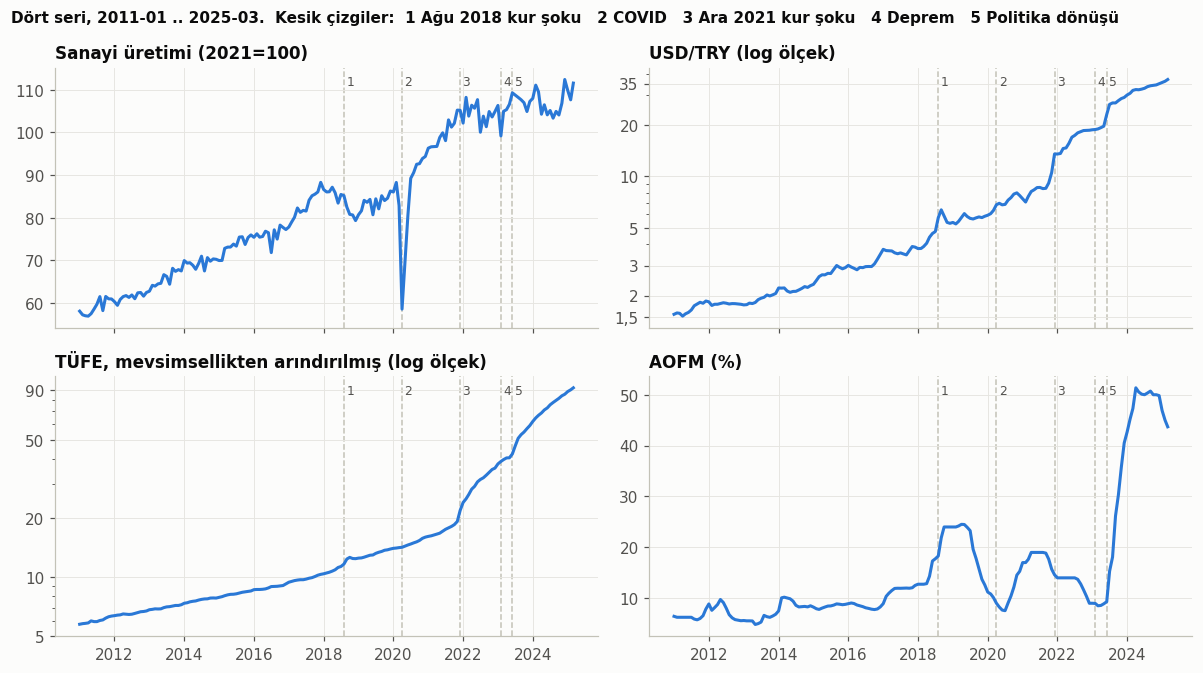

In [3]:
ham = pd.read_csv(VERI_YOLU, index_col="tarih", parse_dates=True)
veri = pd.DataFrame({
    "sue":    100 * np.log(ham["sue"]),
    "usdtry": 100 * np.log(ham["usdtry"]),
    "tufe":   100 * np.log(ham["tufe"]),
    "aofm":   ham["aofm"],
})
DEGISKENLER = list(veri.columns)
AD = {"sue": "Sanayi üretimi", "usdtry": "USD/TRY", "tufe": "TÜFE", "aofm": "AOFM"}
KIRILMALAR = {"2018-08": "Ağu 2018 kur şoku", "2020-04": "COVID", "2021-12": "Ara 2021 kur şoku",
              "2023-02": "Deprem", "2023-06": "Politika dönüşü"}
assert veri.index.max() < pd.Timestamp("2025-04-01"), "Kasa dönemi veriye sızmış!"
print(f"{veri.index.min():%Y-%m} .. {veri.index.max():%Y-%m}, {len(veri)} ay, eksik: {int(veri.isna().sum().sum())}")

from matplotlib.ticker import FuncFormatter, NullFormatter

fig, eksen = plt.subplots(2, 2, figsize=(11, 6.2), sharex=True)
paneller = [("sue", "Sanayi üretimi (2021=100)", None), ("usdtry", "USD/TRY (log ölçek)", [1.5, 2, 3, 5, 10, 20, 35]),
            ("tufe", "TÜFE, mevsimsellikten arındırılmış (log ölçek)", [5, 10, 20, 50, 90]), ("aofm", "AOFM (%)", None)]
for ax, (ad, baslik, log_isaretler) in zip(eksen.flat, paneller):
    ax.plot(ham.index, ham[ad], color=RENK["mavi"])
    if log_isaretler:
        ax.set_yscale("log")
        ax.set_yticks(log_isaretler)
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}".replace(".", ",")))
        ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set_title(baslik, loc="left")
    for no, t in enumerate(KIRILMALAR, 1):
        ax.axvline(pd.Timestamp(t), color=RENK["acik_gri"], lw=1, ls="--", zorder=0)
        ax.text(pd.Timestamp(t) + pd.Timedelta(days=25), 0.97, str(no), transform=ax.get_xaxis_transform(),
                va="top", fontsize=8, color=RENK["gri"])
aciklama = "   ".join(f"{no} {etiket}" for no, etiket in enumerate(KIRILMALAR.values(), 1))
fig.suptitle(f"Dört seri, 2011-01 .. 2025-03.  Kesik çizgiler:  {aciklama}", x=0.01, ha="left", fontweight="bold", fontsize=10)
fig.tight_layout()
plt.show()

Grafiğe bakarken şunu aklında tut: model bu 14 yılın hepsini **tek bir sabit katsayı kümesiyle** açıklamaya çalışacak.
Kur ve TÜFE 2018'den sonra çok daha dik tırmanıyor; AOFM 2021'de enflasyon yükselirken düşüyor, 2023 ortasından sonra hızla yükseliyor.
Bu rejim değişikliklerinin bedelini 10. bölümde konuşacağız.

## 3. Klasik VAR(12): ezberleme

Önce prior'sız, sıradan OLS ile tahmin edelim. Tek ihtiyacımız, her $y_t$ satırının yanına geçmiş $p$ ayın değerlerini dizen bir **gecikme matrisi**:

$$Y = \begin{bmatrix} y_{p+1}' \\ \vdots \\ y_T' \end{bmatrix},\qquad
X = \begin{bmatrix} y_p' & y_{p-1}' & \cdots & y_1' & 1 \\ \vdots & & & & \vdots \\ y_{T-1}' & y_{T-2}' & \cdots & y_{T-p}' & 1 \end{bmatrix},\qquad
Y = XB + U$$

$B$ matrisinin her **sütunu** bir denklem, her **satırı** bir açıklayıcı (gecikme × değişken, en sonda sabit). OLS: $\hat B = (X'X)^{-1}X'Y$.

In [4]:
def gecikme_matrisi(Y, p):
    # Y: T×n. Döndürür: Y_t, (T-p)×n ve X_t = [y_{t-1}, ..., y_{t-p}, 1], (T-p)×(np+1)
    T, n = Y.shape
    X = np.hstack([Y[p - l : T - l] for l in range(1, p + 1)] + [np.ones((T - p, 1))])
    return Y[p:], X


def katsayi(B, denklem, degisken, p, n=4):
    # B içinden "denklem" sütununda "degisken"in 1..p gecikmelerinin katsayıları
    i, j = DEGISKENLER.index(denklem), DEGISKENLER.index(degisken)
    return np.array([B[l * n + j, i] for l in range(p)])


P = 12
Y_tum = veri.values
Y, X = gecikme_matrisi(Y_tum, P)
B_ols = np.linalg.lstsq(X, Y, rcond=None)[0]
print(f"Y: {Y.shape}, X: {X.shape}, B: {B_ols.shape}")
print(f"Denklem başına {X.shape[1]} katsayı, {X.shape[0]} gözlem, serbestlik derecesi {X.shape[0] - X.shape[1]}")

# Standart hatalar: se(B_ij) = sqrt( (X'X)^-1_ii * Σ_jj )
U = Y - X @ B_ols
Sigma_ols = U.T @ U / (X.shape[0] - X.shape[1])
se_ols = np.sqrt(np.outer(np.diag(np.linalg.inv(X.T @ X)), np.diag(Sigma_ols)))
t_gecikme = (B_ols / se_ols)[:-1]          # sabit hariç 192 gecikme katsayısı
print(f"{t_gecikme.size} gecikme katsayısından |t| > 2 olan: {(np.abs(t_gecikme) > 2).sum()}"
      f"   (hepsi gerçekte sıfır olsaydı, şans eseri beklenen: ~{0.046 * t_gecikme.size:.0f})")

Y: (159, 4), X: (159, 49), B: (49, 4)
Denklem başına 49 katsayı, 159 gözlem, serbestlik derecesi 110
192 gecikme katsayısından |t| > 2 olan: 23   (hepsi gerçekte sıfır olsaydı, şans eseri beklenen: ~9)


TÜFE denklemine bakalım: kurun 1..12. gecikmelerinin katsayıları ve ±2 standart hata çubukları (kabaca %95 güven aralığı).

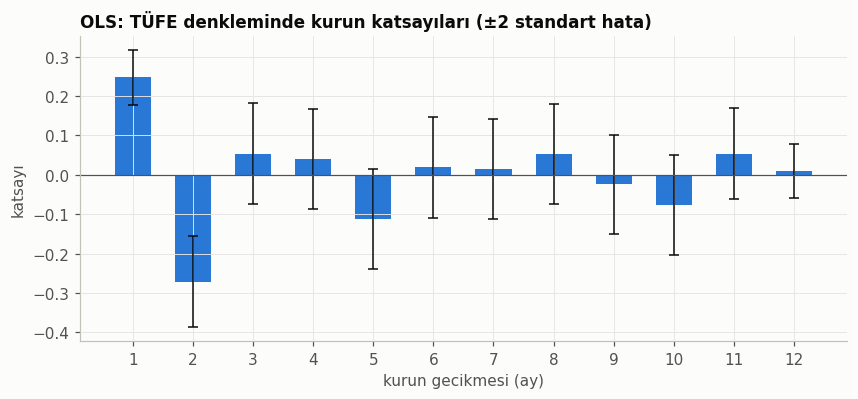

|t| > 2 olan gecikmeler: [1, 2]


In [5]:
k_ols = katsayi(B_ols, "tufe", "usdtry", P)
i_t, j_k = DEGISKENLER.index("tufe"), DEGISKENLER.index("usdtry")
se_k = np.array([se_ols[l * 4 + j_k, i_t] for l in range(P)])

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(range(1, P + 1), k_ols, color=RENK["mavi"], width=0.6)
ax.errorbar(range(1, P + 1), k_ols, yerr=2 * se_k, fmt="none", ecolor="#0b0b0b", elinewidth=1, capsize=3)
ax.axhline(0, color=RENK["gri"], lw=0.8)
ax.set_xticks(range(1, P + 1)); ax.set_xlabel("kurun gecikmesi (ay)"); ax.set_ylabel("katsayı")
ax.set_title("OLS: TÜFE denkleminde kurun katsayıları (±2 standart hata)", loc="left")
plt.show()
print("|t| > 2 olan gecikmeler:", [l + 1 for l in range(P) if abs(k_ols[l] / se_k[l]) > 2])

Üç gözlem:

1. **İlk iki gecikme bir çift.** Yaklaşık +0,25 ve −0,27 yan yana duruyor. Düzeyde çalışırken $a\,e_{t-1} - a\,e_{t-2} = a\,\Delta e_{t-1}$: "geçen ayki kur **artışı** bu ay fiyatları artırır". Bu ekonomik olarak anlamlı.
2. **Sonrası gürültü.** 3-12. gecikmelerin hata çubuklarının hepsi sıfırı kapsıyor. Model yalnızca bu tek değişken çifti için 10 katsayıyı, neredeyse hiçbir şey öğrenmeden harcıyor.
   Bütün modelde 192 gecikme katsayısından yalnızca 23'ü |t| > 2; hepsi gerçekte sıfır olsaydı bile şans eseri 9 kadarı bu eşiği geçerdi.
3. **Ezberleme kendini burada ilan etmez.** Katsayılar tek tek bakınca makul görünüyor. Asıl bedel, bu gürültünün etki-tepkilerde ve tahminlerde birikmesi (8. bölüm).
   Gerçek veride OLS'nin ne kadar yanıldığını ölçemeyiz, çünkü doğruyu bilmiyoruz. Ezberlemenin temiz kanıtını 7. bölümde, doğruyu bildiğimiz yapay bir dünyada göreceğiz.

Çare, katsayılara "makul" bir yer göstermek: veri güçlü konuşmuyorsa sıfıra yakın dursunlar. Bunun adı prior.

## 4. Bayes'e tek parametreyle giriş

Bir an VAR'ı unutalım. Tek bir katsayı $\beta$'yı 12 gözlemle tahmin ediyoruz:
$y_i = \beta x_i + \varepsilon_i,\; \varepsilon_i \sim N(0, \sigma^2)$. Gerçek değer 0,3; biz biliyoruz, model bilmiyor.

Bayesçi tahminin üç parçası var:

- **Prior** $p(\beta)$: veriyi görmeden önceki inanç. Burada $\beta \sim N(0, \tau^2)$: "etki muhtemelen küçük; τ ne kadar küçükse o kadar eminim".
- **Olabilirlik** $p(y \mid \beta)$: veri her β değerini ne kadar destekliyor? Tepesi OLS tahmininde.
- **Posterior** $p(\beta \mid y) \propto p(y \mid \beta)\, p(\beta)$: ikisinin çarpımı.

Normal-normal durumda posterior ortalaması bir **ağırlıklı ortalamadır**:

$$\bar\beta = w\,\hat\beta_{OLS} + (1-w)\cdot 0, \qquad w = \frac{x'x/\sigma^2}{x'x/\sigma^2 + 1/\tau^2}$$

Ağırlıklar **hassasiyetler** (varyansın tersi). Veri bilgisi çoksa ($x'x$ büyük) $w \to 1$, prior silinir.
Prior sıkıysa (τ küçük) $w \to 0$, tahmin prior'a çekilir. **Küçültme** (*shrinkage*) budur.

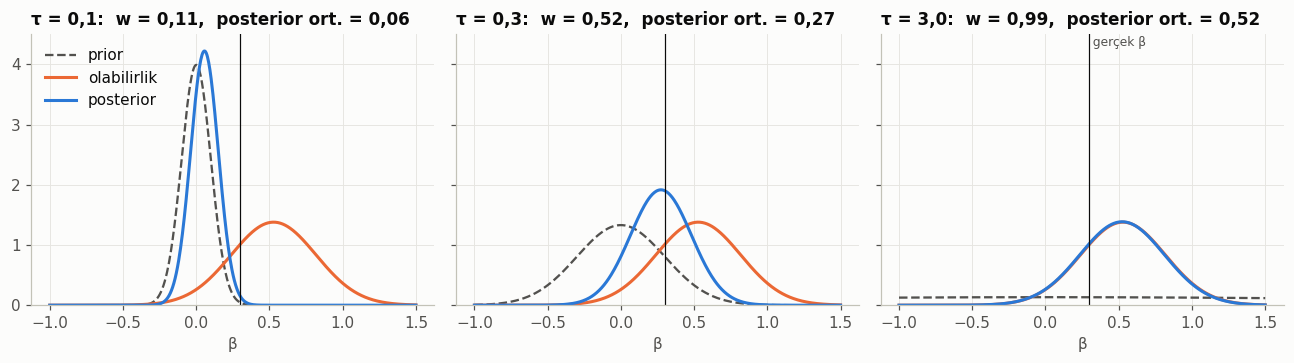

OLS tahmini: 0.528  (gerçek: 0.3)


In [6]:
rng_1 = np.random.default_rng(4)
beta_gercek, sigma_e, T1 = 0.3, 1.0, 12
x1 = rng_1.standard_normal(T1)
y1 = beta_gercek * x1 + sigma_e * rng_1.standard_normal(T1)
b_ols = (x1 @ y1) / (x1 @ x1)


def posterior(tau):
    h_veri, h_prior = (x1 @ x1) / sigma_e**2, 1 / tau**2
    w = h_veri / (h_veri + h_prior)
    return w * b_ols, np.sqrt(1 / (h_veri + h_prior)), w


izgara = np.linspace(-1, 1.5, 600)
fig, eksen = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, tau in zip(eksen, [0.1, 0.3, 3.0]):
    ort, sd, w = posterior(tau)
    ax.plot(izgara, norm.pdf(izgara, 0, tau), color=RENK["gri"], ls="--", lw=1.5, label="prior")
    ax.plot(izgara, norm.pdf(izgara, b_ols, sigma_e / np.sqrt(x1 @ x1)), color=RENK["turuncu"], label="olabilirlik")
    ax.plot(izgara, norm.pdf(izgara, ort, sd), color=RENK["mavi"], label="posterior")
    ax.axvline(beta_gercek, color="#0b0b0b", lw=0.8)
    ax.set_title(f"τ = {tr(tau, 1)}:  w = {tr(w)},  posterior ort. = {tr(ort)}", loc="left")
    ax.set_xlabel("β")
eksen[0].set_ylim(0, 4.5)
eksen[0].legend(loc="upper left")
eksen[2].text(beta_gercek, 4.3, " gerçek β", fontsize=8, color=RENK["gri"])
fig.tight_layout()
plt.show()
print(f"OLS tahmini: {b_ols:.3f}  (gerçek: {beta_gercek})")

Okuma: τ = 0,1'de prior baskın; posterior veri ne derse desin sıfıra yakın kalıyor. τ = 3'te prior neredeyse düz; posterior olabilirlikle örtüşüyor (Bayes ≈ OLS). τ = 0,3 ikisinin arası.

Bu örneklemde OLS (≈ 0,53) gerçeği (0,3) aşmış; τ = 0,3 ile posterior gerçeğe daha yakın. Ama bu şans: başka bir örneklemde OLS gerçeğin altında kalabilir ve küçültme bu kez zarar verir.
Hangisi ortalamada kazanır? Tek bir örneklemle bilemeyiz. 7. bölümde aynı soruyu yüzlerce yapay örneklemle soracağız.

### Sahte gözlem hilesi

Dersin geri kalanını taşıyan eşdeğerlik şu: $N(0, \tau^2)$ prior'ı, veriye **tek bir hayali gözlem** eklemekle aynı şeydir:

$$x^* = \sigma / \tau, \qquad y^* = 0$$

Bu satır "x büyükken y sıfırdı" diyerek eğimi sıfıra çeker. τ küçüldükçe $x^*$ büyür, çekim güçlenir. Sonra **sıradan OLS** çalıştırırsın:

In [7]:
tau = 0.3
x_ek, y_ek = np.append(x1, sigma_e / tau), np.append(y1, 0.0)
print(f"Formülle posterior ortalaması : {posterior(tau)[0]:.6f}")
print(f"Sahte gözlemli OLS            : {(x_ek @ y_ek) / (x_ek @ x_ek):.6f}")

Formülle posterior ortalaması : 0.273728
Sahte gözlemli OLS            : 0.273728


Aynı sayı. 6. bölümde BVAR'ı bu hileyle kuracağız: Minnesota prior'ını birkaç düzine sahte satır olarak veriye ekleyip OLS yapacağız. Bütün Bayesçi makine bu kadar.

<details><summary><b>Kendini sına:</b> Gözlem sayısını 12'den 1200'e çıkarsak, τ = 0,1 ile posterior ortalaması nereye gider?</summary>

$x'x$ yaklaşık 1200'e çıkar; veri hassasiyeti 1200, prior hassasiyeti $1/0{,}1^2 = 100$. Ağırlık $w = 1200/1300 \approx 0{,}92$ olur, posterior OLS'ye (≈ 0,3) yaklaşır.
Çok veri prior'ı ezer. Prior en çok küçük örneklemde önemlidir; 14 yıllık aylık Türkiye verisi tam olarak böyle bir örneklem.
</details>

## 5. Minnesota prior'ı

Litterman (1986) Minneapolis Fed'de basit bir fikirle geldi: Makro serilerin çoğu kısa vadede kabaca **rassal yürüyüş** gibi davranır ($y_t \approx y_{t-1}$). O hâlde VAR katsayılarına şöyle bir prior koyalım.

**Ortalama:** Her denklemde kendi ilk gecikmesinin katsayısı $\delta_i$, diğer bütün katsayılar 0.
Düzeydeki seriler için $\delta = 1$ (rassal yürüyüş), büyüme oranları için $\delta = 0$ (beyaz gürültü). Biz düzey kullandığımız için $\delta = 1$.

**Standart sapma:** $i$. denklemde, $j$. değişkenin $l$. gecikmesinin katsayısı için

$$\text{sd}\big[A_l^{(ij)}\big] = \begin{cases} \dfrac{\lambda}{l^{d}} & i = j \quad \text{(kendi gecikmesi)} \\[2ex] \dfrac{\lambda\,\theta}{l^{d}}\cdot\dfrac{\sigma_i}{\sigma_j} & i \neq j \quad \text{(başka değişkenin gecikmesi)} \end{cases}$$

| Ayar | Ne yapar | Bu derste |
|---|---|---|
| **λ** | Genel sıkılık; bütün prior'ı birlikte daraltır ya da gevşetir. Dersin yıldızı. | 8. bölümde veri seçecek |
| **d** | Gecikme sönümü; uzak gecikmeler sıfıra daha güçlü çekilir. | 1 |
| **θ** | Çapraz küçültme: "başka değişkenlerin etkisi, kendi geçmişinden daha az". | 1 (aşağıdaki nota bak) |
| **σᵢ/σⱼ** | Birim düzeltmesi; oynak kurla sakin TÜFE'yi aynı ölçeğe getirir. | Tek değişkenli AR(1) artıklarının std'si |

> **θ = 1 notu.** Litterman'ın orijinal prior'ı θ < 1 ile başka değişkenleri daha sert küçültür. Bizim kullanacağımız
> "doğal eşlenik" (Normal-ters Wishart) sürümde prior kovaryansı $\Sigma \otimes \Omega$ biçiminde olmak zorunda.
> Bu yapı her denkleme aynı $\Omega$'yı dayatır, dolayısıyla θ = 1'i zorunlu kılar. Karşılığında kapalı formül,
> hızlı çekiliş ve marjinal olabilirlik kazanırız. θ < 1 isteyen, bağımsız Normal-Wishart prior'ı ve Gibbs örneklemesi kullanır.

,σ (AR(1) artık std)
Sanayi üretimi,4.064
USD/TRY,4.055
TÜFE,1.560
AOFM,1.410


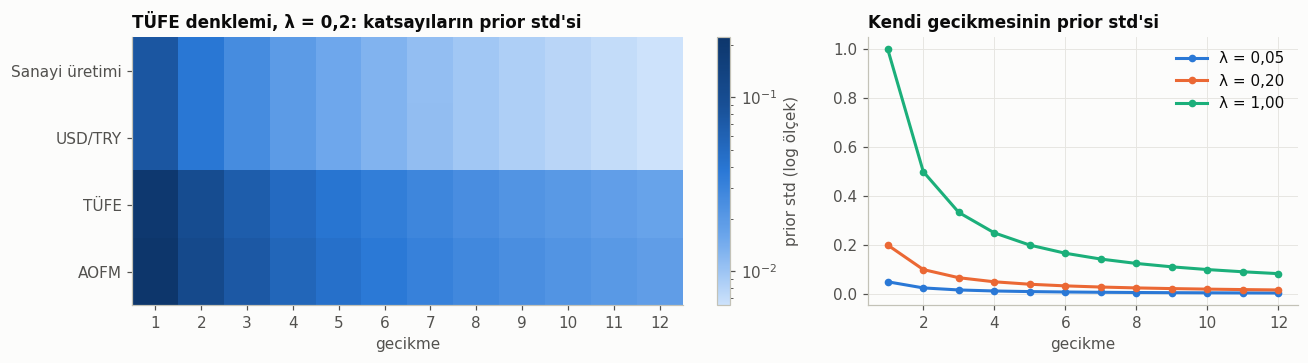

In [8]:
def ar1_sigma(Y):
    # Her seri için sabitli AR(1) artıklarının standart sapması (prior'ın ölçeği)
    s = []
    for i in range(Y.shape[1]):
        y, x = Y[1:, i], np.column_stack([Y[:-1, i], np.ones(len(Y) - 1)])
        b = np.linalg.lstsq(x, y, rcond=None)[0]
        s.append(np.std(y - x @ b, ddof=2))
    return np.array(s)


def minnesota_sd(lam, sigma, p, denklem, d=1.0):
    # denklem: indeks. Döndürür: n×p prior std matrisi (satır = değişken, sütun = gecikme)
    l = np.arange(1, p + 1) ** d
    oran = sigma[denklem] / sigma
    oran[denklem] = 1.0
    return lam * oran[:, None] / l[None, :]


sigma = ar1_sigma(Y_tum)
display(pd.Series(sigma, index=[AD[d] for d in DEGISKENLER], name="σ (AR(1) artık std)").round(3).to_frame())

sd_tufe = minnesota_sd(0.2, sigma, P, DEGISKENLER.index("tufe"))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1.6, 1]})
im = ax1.imshow(sd_tufe, aspect="auto", cmap=MAVI_SKALA, norm=LogNorm())
ax1.set_yticks(range(4)); ax1.set_yticklabels([AD[d] for d in DEGISKENLER])
ax1.set_xticks(range(P)); ax1.set_xticklabels(range(1, P + 1)); ax1.set_xlabel("gecikme")
ax1.grid(False)
ax1.set_title("TÜFE denklemi, λ = 0,2: katsayıların prior std'si", loc="left")
fig.colorbar(im, ax=ax1, label="prior std (log ölçek)")
for lam, renk in [(0.05, RENK["mavi"]), (0.2, RENK["turuncu"]), (1.0, RENK["su"])]:
    ax2.plot(range(1, P + 1), minnesota_sd(lam, sigma, P, 2)[2], marker="o", ms=4, color=renk, label=f"λ = {tr(lam)}")
ax2.set_xlabel("gecikme"); ax2.set_title("Kendi gecikmesinin prior std'si", loc="left")
ax2.legend()
fig.tight_layout()
plt.show()

Soldaki ısı haritası prior'ın "izin verdiği" alanı gösteriyor: koyu hücreler daha geniş serbestlik demek.
Kendi gecikmeleri (TÜFE satırı) en serbest; uzak gecikmelere gidildikçe her satır açılıyor (d = 1). Satırlar arasındaki fark tamamen σ oranından geliyor.
Sağdaki grafik λ'nın ne yaptığını gösteriyor: bütün eğriyi yukarı aşağı kaydırıyor, şeklini değiştirmiyor.

Tabloda bir tuhaflık var: sanayi üretiminin σ'sı kurunki kadar büyük. Sebebi büyük ölçüde tek bir ay: 2020 Nisan'daki COVID çöküşü.
Tek bir olağan dışı gözlem prior'ın ölçeğini değiştirebiliyor; 10. bölümde buna döneceğiz.

<details><summary><b>Kendini sına:</b> TÜFE denkleminde AOFM gecikmelerinin prior std'si, kurunkinin yaklaşık üç katı. Neden? (σ tablosuna bak.)</summary>

Formüldeki $\sigma_{TÜFE}/\sigma_j$ oranı yüzünden. Kur için $1{,}56/4{,}06 \approx 0{,}38$, AOFM için $1{,}56/1{,}41 \approx 1{,}11$; aradaki fark kabaca 2,9 kat.
Bu bir "kur önemsizdir" inancı değil, **birim düzeltmesi**. Kurdaki 1 log puanlık aylık sürpriz sıradan bir olay; AOFM'deki 1 puanlık sürpriz ise çok daha büyük bir olay.
Katsayı "değişkenin bir birimi başına" tanımlandığı için doğal ölçeği de buna göre değişiyor.
</details>

## 6. BVAR'ı sıfırdan kurmak

4. bölümdeki hileyi VAR'a uyguluyoruz (Bańbura, Giannone ve Reichlin 2010). Minnesota prior'ı, üç bloktan oluşan sahte gözlemlerle yazılır:

$$Y_d = \begin{bmatrix} \text{diag}(\delta_1\sigma_1, \dots, \delta_n\sigma_n)/\lambda \\ 0_{n(p-1)\times n} \\ \text{diag}(\sigma_1, \dots, \sigma_n) \\ 0_{1\times n} \end{bmatrix}, \qquad
X_d = \begin{bmatrix} J_p \otimes \text{diag}(\sigma_1, \dots, \sigma_n)/\lambda & 0 \\ 0_{n\times np} & 0 \\ 0_{1\times np} & \varepsilon \end{bmatrix}, \qquad J_p = \text{diag}(1^d, \dots, p^d)$$

1. **İlk blok** gecikme katsayılarına prior koyar. Birinci gecikmenin satırları "$y_t$ dünkü değerine $\delta$ kere eşit" der; diğer gecikmelerin satırları "katsayılar 0", ve $l^d$ çarpanı uzak gecikmeleri daha sert sıfıra çeker.
2. **İkinci blok** $\Sigma$ hakkında ılımlı bir prior koyar (şokların ölçeği kabaca $\sigma_i$).
3. **Son satır** sabit terime çok gevşek bir prior koyar (ε = 0,0001).

λ küçükse sahte satırlar büyür ve veriye baskın gelir. Küçük bir örnekte ($n = 2,\ p = 2$) matrislere bakalım:

In [9]:
def sahte_gozlemler(sigma, delta, lam, p, d=1.0, eps=1e-4):
    n = len(sigma)
    Jp = np.diag(np.arange(1, p + 1) ** d)
    Yd = np.vstack([np.diag(delta * sigma) / lam,      # 1) gecikme katsayıları
                    np.zeros((n * (p - 1), n)),
                    np.diag(sigma),                    # 2) Σ
                    np.zeros((1, n))])                 # 3) sabit
    Xd = np.zeros((n * p + n + 1, n * p + 1))
    Xd[: n * p, : n * p] = np.kron(Jp, np.diag(sigma)) / lam
    Xd[-1, -1] = eps
    return Yd, Xd


ornek_Yd, ornek_Xd = sahte_gozlemler(np.array([2.0, 0.5]), np.ones(2), lam=0.2, p=2)
satir = ["gecikme1: kur", "gecikme1: tüfe", "gecikme2: kur", "gecikme2: tüfe", "Σ: kur", "Σ: tüfe", "sabit"]
print("Y_d  (sütunlar: denklemler)")
display(pd.DataFrame(ornek_Yd, index=satir, columns=["kur", "tüfe"]).round(2))
print("X_d  (sütunlar: açıklayıcılar)")
display(pd.DataFrame(ornek_Xd, index=satir, columns=["kur(t-1)", "tüfe(t-1)", "kur(t-2)", "tüfe(t-2)", "sabit"]).round(4))

Y_d  (sütunlar: denklemler)


,kur,tüfe
gecikme1: kur,10.0,0.0
gecikme1: tüfe,0.0,2.5
gecikme2: kur,0.0,0.0
gecikme2: tüfe,0.0,0.0
Σ: kur,2.0,0.0
Σ: tüfe,0.0,0.5
sabit,0.0,0.0


X_d  (sütunlar: açıklayıcılar)


,kur(t-1),tüfe(t-1),kur(t-2),tüfe(t-2),sabit
gecikme1: kur,10.0,0.0,0.0,0.0,0.0000
gecikme1: tüfe,0.0,2.5,0.0,0.0,0.0000
gecikme2: kur,0.0,0.0,20.0,0.0,0.0000
gecikme2: tüfe,0.0,0.0,0.0,5.0,0.0000
Σ: kur,0.0,0.0,0.0,0.0,0.0000
Σ: tüfe,0.0,0.0,0.0,0.0,0.0000
sabit,0.0,0.0,0.0,0.0,0.0001


İlk satırı oku: $Y_d$'de kur denkleminde 10, $X_d$'de kur(t-1) sütununda 10. Yani "kur(t-1) = 10 iken kur(t) = 10 idi": kurun kendi gecikmesinin katsayısını 1'e çeken hayali bir gözlem.
Üçüncü satırda $X_d$'deki değer iki katı (20), $Y_d$ sıfır: ikinci gecikmeyi sıfıra daha sert çeken bir gözlem ($l^d = 2$).

### Posterior

Sahte satırları veriye ekle: $Y_* = [Y;\, Y_d]$, $X_* = [X;\, X_d]$. Sonra:

$$\tilde B = (X_*'X_*)^{-1} X_*'Y_*, \qquad \tilde S = (Y_* - X_*\tilde B)'(Y_* - X_*\tilde B)$$
$$\Sigma \mid Y \sim \mathcal{IW}(\tilde S,\; T_* - k), \qquad \text{vec}(B) \mid \Sigma, Y \sim N\big(\text{vec}(\tilde B),\; \Sigma \otimes (X_*'X_*)^{-1}\big)$$

$\tilde B$ posterior ortalaması: sahte gözlemli OLS, 4. bölümdekiyle aynı. Belirsizlik için $\Sigma$'yı ters Wishart'tan, sonra $B$'yi normalden çekeriz.

### Marjinal olabilirlik

λ'yı seçmek için şu soruyu soracağız: **"Bu λ ile kurulmuş bir model, veriyi görmeden önce bu veriyi ne kadar olası bulurdu?"**
Bu sayı $p(Y \mid \lambda)$, marjinal olabilirlik. Bu modelde kapalı formülü var:

$$\log p(Y \mid \lambda) = \log m(Y_*, X_*) - \log m(Y_d, X_d), \qquad
m(Y, X) = \pi^{-\frac{n(T-k)}{2}}\, |X'X|^{-\frac{n}{2}}\, \Gamma_n\!\big(\tfrac{T-k}{2}\big)\, |S|^{-\frac{T-k}{2}}$$

Sezgisi: Çok sıkı bir prior (λ küçük) veriyi kötü tahmin eder, çünkü gerçek dinamiklere izin vermez.
Çok gevşek bir prior (λ büyük) olasılığı uçsuz bucaksız bir katsayı uzayına dağıtır; gözlenen veriye düşen pay küçülür.
Marjinal olabilirlik bu ikisini **kendiliğinden** dengeler: içine yerleşik bir Occam usturası var.

In [10]:
def log_m(Y, X):
    T, n = Y.shape
    k = X.shape[1]
    XtX = X.T @ X
    E = Y - X @ np.linalg.solve(XtX, X.T @ Y)
    return (-n * (T - k) / 2 * np.log(np.pi) - n / 2 * np.linalg.slogdet(XtX)[1]
            + multigammaln((T - k) / 2, n) - (T - k) / 2 * np.linalg.slogdet(E.T @ E)[1])


def bvar_kur(Y_tum, p, lam, delta=None, d=1.0):
    Y, X = gecikme_matrisi(Y_tum, p)
    n = Y.shape[1]
    sigma = ar1_sigma(Y_tum)
    delta = np.ones(n) if delta is None else np.asarray(delta, float)
    Yd, Xd = sahte_gozlemler(sigma, delta, lam, p, d)
    Ys, Xs = np.vstack([Y, Yd]), np.vstack([X, Xd])
    XtX = Xs.T @ Xs
    B = np.linalg.solve(XtX, Xs.T @ Ys)
    E = Ys - Xs @ B
    S = E.T @ E
    nu = Ys.shape[0] - Xs.shape[1]
    return {"B": B, "S": S, "nu": nu, "XtX_inv": np.linalg.inv(XtX), "n": n, "p": p, "lam": lam,
            "Sigma": S / (nu - n - 1),           # ters Wishart'ın ortalaması
            "log_ml": log_m(Ys, Xs) - log_m(Yd, Xd), "Y_son": Y_tum[-p:]}


# İki uç durum: tanım gereği bunları sağlamalı
gevsek = bvar_kur(Y_tum, P, lam=1e3)
siki = bvar_kur(Y_tum, P, lam=1e-3)
print(f"λ = 1000  ->  OLS'den en büyük fark          : {np.abs(gevsek['B'][:-1] - B_ols[:-1]).max():.5f}")
print(f"λ = 0.001 ->  A1'in birim matristen en büyük farkı: {np.abs(siki['B'][:4] - np.eye(4)).max():.5f}")
print(f"λ = 0.001 ->  A2..A12 katsayılarının en büyüğü    : {np.abs(siki['B'][4:-1]).max():.5f}")

λ = 1000  ->  OLS'den en büyük fark          : 0.00002
λ = 0.001 ->  A1'in birim matristen en büyük farkı: 0.00315
λ = 0.001 ->  A2..A12 katsayılarının en büyüğü    : 0.00075


İki uç doğru çalışıyor: λ çok büyükken BVAR = OLS, λ çok küçükken BVAR = "her seri rassal yürüyüş". Arada bir yerde, ikisinin bir karışımı var.

Son olarak, posterior'dan çekiliş yapan, etki-tepki ve tahmin üreten araçlar. Bunlar her VAR'da aynı; Bayesçi olan tek şey, tek bir $\hat B$ yerine binlerce $B$ çekilişi üzerinde çalışmaları.

In [11]:
def eslik_matrisi(B, n, p):
    # VAR(p)'yi VAR(1) gibi yazmak için "companion" matris
    F = np.zeros((n * p, n * p))
    F[:n] = B[: n * p].T
    F[n:, :-n] = np.eye(n * (p - 1))
    return F


def en_buyuk_kok(B, n, p):
    return np.max(np.abs(np.linalg.eigvals(eslik_matrisi(B, n, p))))


def cekilisler(model, adet=1000, rng=rng, kok_siniri=1.02):
    # Posterior'dan (B, Σ) çekilişleri. Patlayan (kökü > kok_siniri) çekilişler atılır.
    L_V = np.linalg.cholesky(model["XtX_inv"])
    n, p = model["n"], model["p"]
    B_ler, S_ler, atilan = [], [], 0
    while len(B_ler) < adet and atilan < 5 * adet:
        Sig = invwishart.rvs(df=model["nu"], scale=model["S"], random_state=rng)
        B = model["B"] + L_V @ rng.standard_normal(model["B"].shape) @ np.linalg.cholesky(Sig).T
        if en_buyuk_kok(B, n, p) > kok_siniri:
            atilan += 1
            continue
        B_ler.append(B)
        S_ler.append(Sig)
    return np.array(B_ler), np.array(S_ler), atilan / (atilan + len(B_ler))


def etki_tepki(B, Sig, n, p, sok, buyukluk=10.0, ufuk=36, sira=None):
    # Cholesky tanımlaması. sira: değişkenlerin "eşzamanlılık" sırası (varsayılan: DEGISKENLER)
    sira = list(range(n)) if sira is None else sira
    L = np.zeros((n, n))
    L[np.ix_(sira, sira)] = np.linalg.cholesky(Sig[np.ix_(sira, sira)])
    etki = L[:, sok] * buyukluk / L[sok, sok]     # şok, kendi değişkenini ilk ayda "buyukluk" kadar oynatır
    F = eslik_matrisi(B, n, p)
    durum = np.zeros(n * p)
    durum[:n] = etki
    cikti = np.zeros((ufuk + 1, n))
    cikti[0] = etki
    for h in range(1, ufuk + 1):
        durum = F @ durum
        cikti[h] = durum[:n]
    return cikti


def tahmin_yollari(B_ler, S_ler, Y_son, ufuk=12, rng=rng):
    # Her çekiliş için, şoklarıyla birlikte bir gelecek yolu simüle et
    adet, n, p = len(B_ler), Y_son.shape[1], len(Y_son)
    yollar = np.zeros((adet, ufuk, n))
    for d_, (B, Sig) in enumerate(zip(B_ler, S_ler)):
        L = np.linalg.cholesky(Sig)
        gecmis = list(Y_son)
        for h in range(ufuk):
            x = np.concatenate([gecmis[-l] for l in range(1, p + 1)] + [[1.0]])
            y = x @ B + L @ rng.standard_normal(n)
            gecmis.append(y)
            yollar[d_, h] = y
    return yollar


def bant_ciz(ax, x, cekilis, renk, etiket=None, bantlar=((5, 95), (16, 84))):
    # Medyan çizgisi + %68 ve %90 güven bantları
    for (alt, ust), alfa in zip(bantlar, (0.15, 0.3)):
        ax.fill_between(x, np.percentile(cekilis, alt, 0), np.percentile(cekilis, ust, 0), color=renk, alpha=alfa, lw=0)
    ax.plot(x, np.median(cekilis, 0), color=renk, label=etiket)

print("Araçlar hazır.")

Araçlar hazır.


<details><summary><b>Kendini sına:</b> λ → ∞ olduğunda sahte gözlemlere ne olur, BVAR neden OLS'ye döner?</summary>

$Y_d$ ve $X_d$'nin ilk blokları λ'ya bölünüyor; λ büyüdükçe bu satırlar sıfıra gider ve regresyona hiçbir bilgi katmaz.
Geriye yalnızca $\Sigma$ bloğu kalır; o da katsayıları etkilemez ($X_d$'de o satırlar sıfır). Sonuç: $\tilde B = \hat B_{OLS}$.
λ → 0'da ise bu satırlar sonsuz büyür ve katsayıları prior ortalamasına (A1 = I, gerisi 0) kilitler.
</details>

## 7. λ laboratuvarı I: doğruyu bildiğimiz yapay dünya

Gerçek veride "doğru λ"yı bilemeyiz, çünkü gerçek katsayıları bilmiyoruz. Yapay bir dünyada biliyoruz.
Planımız:

1. Bilinen bir **VAR(2)**'den 4 değişkenli, 100 aylık veri üret. Katsayılar makro serilere benzesin: kendi gecikmeleri yüksek (0,75-0,9), birkaç küçük çapraz etki, gerisi sıfır.
2. Üstüne bir **VAR(6)** tahmin et. Gerçek hayatta da doğru gecikme sayısını bilmeyiz; fazlasını koyarız. Fazla gecikmeler, sıfır olması gereken 64 katsayı demek.
3. Bunu farklı λ'larla yap ve üç şeyi ölç: (a) katsayıların gerçek değerlerden uzaklığı, (b) tahminde kullanılmamış 60 aylık yeni veride bir adım ötesi tahmin hatası, (c) marjinal olabilirliğin hangi λ'yı seçtiği.
4. Hepsini 200 kez tekrarla.

Prior burada bilerek biraz yanlış: δ = 1 (rassal yürüyüş) diyor, gerçek kendi katsayıları 0,75-0,9. Gerçek hayatta prior'ın da hiçbir zaman tam doğru olmadığını unutma.

In [12]:
n_y, p_dogru, p_model, T_egitim, T_test, tekrar = 4, 2, 6, 100, 60, 200
A1 = np.array([[0.85, 0.00, 0.00, 0.00],
               [0.10, 0.80, 0.00, -0.10],
               [0.00, 0.15, 0.90, 0.00],
               [0.00, 0.10, 0.10, 0.75]])
A2 = np.diag([-0.10, 0.00, -0.05, 0.10])
Sigma_dogru = np.array([[1.0, 0.3, 0.1, 0.0],
                        [0.3, 2.0, 0.4, 0.3],
                        [0.1, 0.4, 0.5, 0.1],
                        [0.0, 0.3, 0.1, 0.8]])
B_dogru = np.zeros((n_y * p_model + 1, n_y))
B_dogru[:n_y], B_dogru[n_y:2 * n_y] = A1.T, A2.T
print("Gerçek modelin en büyük kökü:", round(en_buyuk_kok(B_dogru, n_y, p_model), 3), "(< 1: durağan)")


def simule_et(T, rng, isinma=200):
    L = np.linalg.cholesky(Sigma_dogru)
    y = np.zeros((T + isinma, n_y))
    for t in range(2, T + isinma):
        y[t] = A1 @ y[t - 1] + A2 @ y[t - 2] + L @ rng.standard_normal(n_y)
    return y[isinma:]


lam_izgara = np.geomspace(0.01, 10, 25)
rng_mc = np.random.default_rng(11)
kat_hata = np.zeros((tekrar, len(lam_izgara)))
tah_hata = np.zeros((tekrar, len(lam_izgara)))
ml = np.zeros((tekrar, len(lam_izgara)))
ols_kat, ols_tah = np.zeros(tekrar), np.zeros(tekrar)
olcek = np.diag(Sigma_dogru)          # tahmin hatasını her değişkenin şok varyansıyla ölçekle


def degerlendir(B, y, egitim_son):
    kat = np.sqrt(np.mean((B[:-1] - B_dogru[:-1]) ** 2))
    Yt, Xt = gecikme_matrisi(y, p_model)
    hata = (Yt - Xt @ B)[egitim_son - p_model:]           # yalnızca test dönemi
    return kat, np.mean(hata**2 / olcek)


for r in range(tekrar):
    y = simule_et(T_egitim + T_test, rng_mc)
    egitim = y[:T_egitim]
    for k, lam in enumerate(lam_izgara):
        m = bvar_kur(egitim, p_model, lam)
        kat_hata[r, k], tah_hata[r, k] = degerlendir(m["B"], y, T_egitim)
        ml[r, k] = m["log_ml"]
    Y_e, X_e = gecikme_matrisi(egitim, p_model)
    B_o = np.linalg.lstsq(X_e, Y_e, rcond=None)[0]
    ols_kat[r], ols_tah[r] = degerlendir(B_o, y, T_egitim)

secilen = lam_izgara[ml.argmax(1)]
en_iyi_tah = lam_izgara[tah_hata.mean(0).argmin()]
print(f"Tahmin hatasını en aza indiren λ (200 tekrar ortalaması): {en_iyi_tah:.3f}")
print(f"Marjinal olabilirliğin seçtiği λ: medyan {np.median(secilen):.3f}, "
      f"%25-%75 aralığı {np.percentile(secilen, 25):.3f} - {np.percentile(secilen, 75):.3f}")
mse_ml = tah_hata[np.arange(tekrar), ml.argmax(1)].mean()
print(f"Ortalama ölçekli tahmin hatası:  en iyi sabit λ ile {tah_hata.mean(0).min():.3f}  |  "
      f"marjinal olabilirliğin her tekrarda seçtiği λ ile {mse_ml:.3f}  |  OLS ile {ols_tah.mean():.3f}")

Gerçek modelin en büyük kökü: 0.887 (< 1: durağan)
Tahmin hatasını en aza indiren λ (200 tekrar ortalaması): 0.075
Marjinal olabilirliğin seçtiği λ: medyan 0.133, %25-%75 aralığı 0.133 - 0.178
Ortalama ölçekli tahmin hatası:  en iyi sabit λ ile 1.062  |  marjinal olabilirliğin her tekrarda seçtiği λ ile 1.083  |  OLS ile 1.452


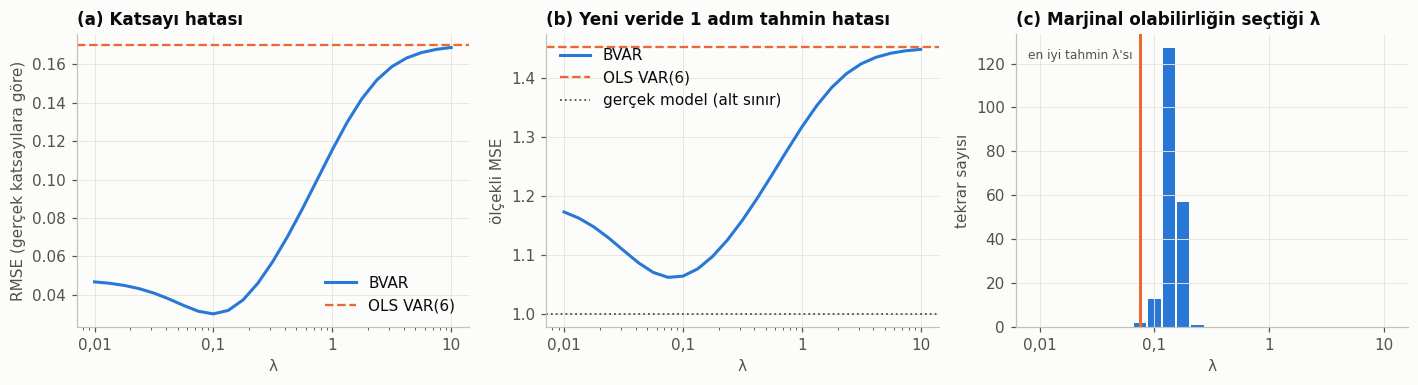

In [13]:
fig, eksen = plt.subplots(1, 3, figsize=(13, 3.6))
ax = eksen[0]
ax.plot(lam_izgara, kat_hata.mean(0), color=RENK["mavi"], label="BVAR")
ax.axhline(ols_kat.mean(), color=RENK["turuncu"], ls="--", lw=1.5, label="OLS VAR(6)")
ax.set_title("(a) Katsayı hatası", loc="left"); ax.set_ylabel("RMSE (gerçek katsayılara göre)")

ax = eksen[1]
ax.plot(lam_izgara, tah_hata.mean(0), color=RENK["mavi"], label="BVAR")
ax.axhline(ols_tah.mean(), color=RENK["turuncu"], ls="--", lw=1.5, label="OLS VAR(6)")
ax.axhline(1.0, color=RENK["gri"], ls=":", lw=1.2, label="gerçek model (alt sınır)")
ax.set_title("(b) Yeni veride 1 adım tahmin hatası", loc="left"); ax.set_ylabel("ölçekli MSE")

for ax in eksen[:2]:
    ax.set_xscale("log"); ax.set_xlabel("λ"); ax.legend()
    ax.set_xticks([0.01, 0.1, 1, 10]); ax.set_xticklabels(["0,01", "0,1", "1", "10"])

ax = eksen[2]
log_izgara = np.log10(lam_izgara)
adim = log_izgara[1] - log_izgara[0]
kenarlar = np.append(log_izgara - adim / 2, log_izgara[-1] + adim / 2)   # her ızgara noktası kendi kutusunun ortasında
ax.hist(np.log10(secilen), bins=kenarlar, color=RENK["mavi"], rwidth=0.85)
ax.axvline(np.log10(en_iyi_tah), color=RENK["turuncu"], lw=2)
ax.text(np.log10(en_iyi_tah), ax.get_ylim()[1] * 0.95, "en iyi tahmin λ'sı  ", color=RENK["gri"], fontsize=8, va="top", ha="right")
ax.set_xticks(np.log10([0.01, 0.1, 1, 10])); ax.set_xticklabels(["0,01", "0,1", "1", "10"])
ax.set_title("(c) Marjinal olabilirliğin seçtiği λ", loc="left"); ax.set_xlabel("λ"); ax.set_ylabel("tekrar sayısı")
fig.tight_layout()
plt.show()

Bu üç grafik dersin özü. Ne görüyoruz:

- **(a) ve (b)'deki U şekli, önyargı-varyans dengesi.** Sol uçta (λ çok küçük) prior katsayıları yanlış bir yere (rassal yürüyüş) kilitliyor: **önyargı**. Sağ uçta (λ büyük) BVAR, OLS'ye yaklaşıyor: katsayılar gürültüyle zıplıyor, **varyans**. Ortada bir yerde toplam hata en düşük.
- **BVAR, OLS'yi geçiyor.** U'nun dibi OLS çizgisinin belirgin biçimde altında. Fazla gecikmeli, küçük örneklemli bir VAR'da küçültme hem katsayıları hem tahminleri iyileştiriyor. Prior biraz yanlış olsa bile.
- **(c) Marjinal olabilirlik iyi bir λ'yı kendi buluyor.** Ne gerçek katsayıları ne test verisini gördü; yalnızca eğitim verisine baktı.
  Seçtiği λ'lar en iyi tahmin λ'sının biraz sağında (bir miktar gevşek) toplanıyor, ama (b)'deki eğrinin dibe yakın, düz bölgesinde.
  Yukarıdaki çıktıya bak: marjinal olabilirliğin seçtiği λ ile ortalama tahmin hatası, en iyi sabit λ'nınkine çok yakın ve OLS'ninkinden çok düşük.
  Gerçek veride elimizdeki tek pusula bu olacak.

<details><summary><b>Kendini sına:</b> Örneklem 100 yerine 1000 ay olsaydı, en iyi λ büyür müydü, küçülür müydü?</summary>

Büyürdü. Çok veride OLS'nin varyansı küçülür, prior'ın önyargısı ise aynı kalır; denge gevşek prior'a kayar.
Bu, 4. bölümdeki "çok veri prior'ı ezer" fikrinin aynısı. Alıştırma 5'te deneyebilirsin.
</details>

## 8. λ laboratuvarı II: gerçek veri

Artık gerçek veriye dönüyoruz. Sıra:

1. Marjinal olabilirlik eğrisi ve λ*.
2. Üç model yan yana: çok sıkı (λ = 0,02), veri seçimi (λ*), çok gevşek (λ = 10 ≈ OLS).
3. Katsayılar, etki-tepkiler ve tahmin bantları bu üç modelde nasıl değişiyor?

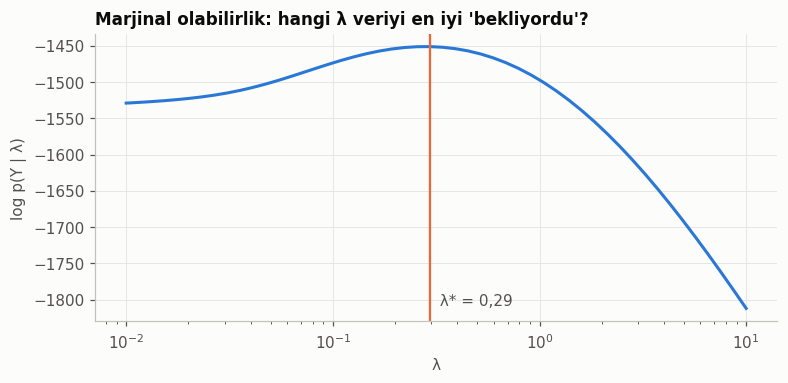

λ = 0,02 (çok sıkı)          log ML =   -1522.8
λ* = 0,29 (veri seçti)       log ML =   -1451.3
λ = 10 (≈ OLS)               log ML =   -1812.0


In [14]:
lam_ml = np.geomspace(0.01, 10, 50)
log_ml = np.array([bvar_kur(Y_tum, P, l)["log_ml"] for l in lam_ml])
LAM_YILDIZ = lam_ml[log_ml.argmax()]

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(lam_ml, log_ml, color=RENK["mavi"])
ax.axvline(LAM_YILDIZ, color=RENK["turuncu"], lw=1.5)
ax.text(LAM_YILDIZ, log_ml.min(), f"  λ* = {tr(LAM_YILDIZ)}", color=RENK["gri"], va="bottom")
ax.set_xscale("log"); ax.set_xlabel("λ"); ax.set_ylabel("log p(Y | λ)")
ax.set_title("Marjinal olabilirlik: hangi λ veriyi en iyi 'bekliyordu'?", loc="left")
plt.show()

MODELLER = {"λ = 0,02 (çok sıkı)": 0.02, f"λ* = {tr(LAM_YILDIZ)} (veri seçti)": LAM_YILDIZ, "λ = 10 (≈ OLS)": 10.0}
MODEL_RENK = dict(zip(MODELLER, [RENK["mavi"], RENK["turuncu"], RENK["su"]]))
for ad, lam in MODELLER.items():
    print(f"{ad:28s} log ML = {bvar_kur(Y_tum, P, lam)['log_ml']:9.1f}")

Eğrinin tepesi belirgin. Literatürde orta büyüklükteki aylık VAR'lar için bulunan değerler (Giannone, Lenza ve Primiceri 2015) genelde 0,1 ile 0,5 arasında; λ* bu aralıkta.

**Rakamları nasıl okumalı:** Log marjinal olabilirlikte 1 birimlik fark, olasılık oranında $e^1 \approx 2{,}7$ kat demek. λ* ile λ = 10 arasındaki yüzlerce birimlik fark, verinin λ = 10'u neredeyse tamamen dışladığı anlamına geliyor.

### Katsayılar ne oldu?

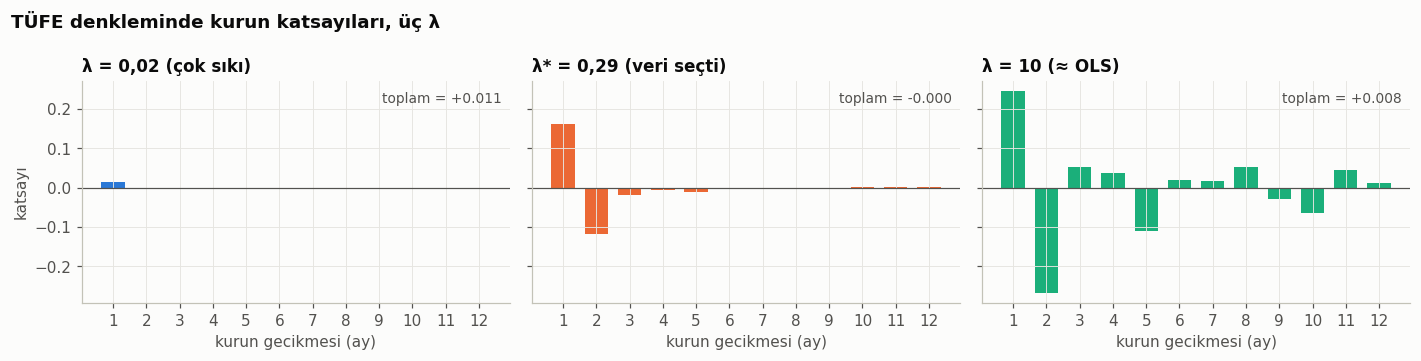

In [15]:
fig, eksen = plt.subplots(1, 3, figsize=(13, 3.3), sharey=True)
for ax, (ad, lam) in zip(eksen, MODELLER.items()):
    k = katsayi(bvar_kur(Y_tum, P, lam)["B"], "tufe", "usdtry", P)
    ax.bar(range(1, P + 1), k, color=MODEL_RENK[ad], width=0.7)
    ax.axhline(0, color=RENK["gri"], lw=0.8)
    ax.set_title(ad, loc="left"); ax.set_xticks(range(1, P + 1)); ax.set_xlabel("kurun gecikmesi (ay)")
    ax.text(0.98, 0.95, f"toplam = {k.sum():+.3f}", transform=ax.transAxes, ha="right", va="top", fontsize=9, color=RENK["gri"])
eksen[0].set_ylabel("katsayı")
fig.suptitle("TÜFE denkleminde kurun katsayıları, üç λ", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

- **λ = 0,02:** Neredeyse her şey sıfır. Model kurun fiyatlara etkisine izin vermiyor; TÜFE "kendi yolunda yürüyen" bir seri.
- **λ = 10:** 3. bölümdeki desen: ilk iki gecikmedeki çift, sonra 10 tane gürültülü küçük katsayı.
- **λ\*:** Çift korunuyor (yaklaşık +0,16 ve −0,12), 3. gecikmeden sonrası neredeyse sıfır. Küçültme, verinin güçlü konuştuğu yeri bırakıyor, zayıf konuştuğu yeri siliyor.

Bedeli de görünüyor: çiftin kendisi de küçüldü (+0,25'ten +0,16'ya). Prior hiçbir katsayıyı "bedavaya" bırakmaz.
Biraz önyargıyı, çok daha az varyans karşılığında kabul ediyoruz. 7. bölümde bu takasın ortalamada kazandırdığını gördük.

### Etki-tepki: üç λ

9. bölümde ayrıntısıyla açacağımız soruyu şimdiden soralım: **Kur bir ayda 10 log puan (≈ %10) şoklanırsa TÜFE düzeyi ne olur?**
Her model için posterior'dan 1000 çekiliş yapıp her çekilişin etki-tepkisini hesaplıyoruz. Koyu bant %68, açık bant %90 güven aralığı.

λ = 0,02 (çok sıkı)          patlayan oldugu icin atilan cekilis payi: 1.9%
λ* = 0,29 (veri seçti)       patlayan oldugu icin atilan cekilis payi: 4.8%
λ = 10 (≈ OLS)               patlayan oldugu icin atilan cekilis payi: 10.2%


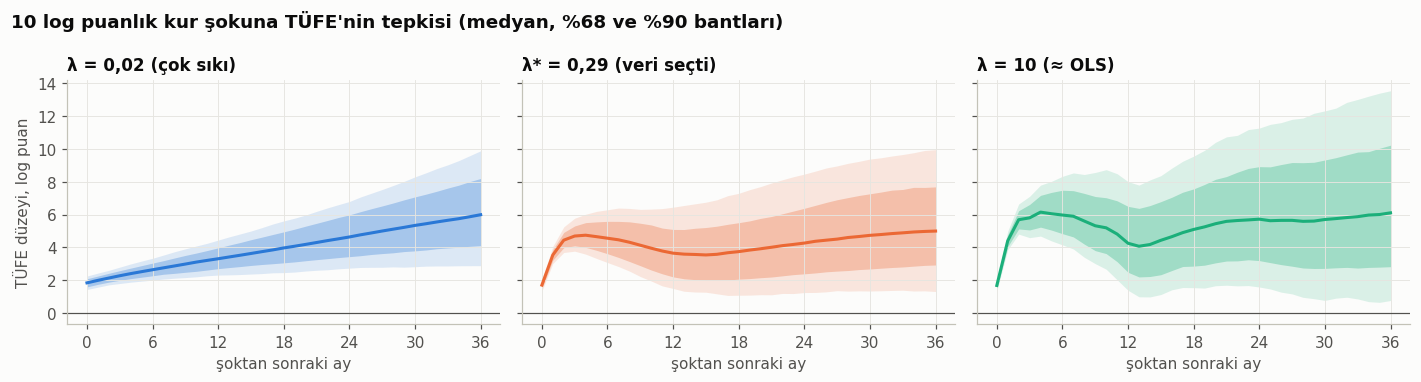

In [16]:
CEKILIS = {}
for ad, lam in MODELLER.items():
    m = bvar_kur(Y_tum, P, lam)
    B_ler, S_ler, atilan_pay = cekilisler(m, adet=1000)
    CEKILIS[ad] = (m, B_ler, S_ler)
    print(f"{ad:28s} patlayan oldugu icin atilan cekilis payi: {atilan_pay:.1%}")

KUR, TUFE = DEGISKENLER.index("usdtry"), DEGISKENLER.index("tufe")
ufuk = np.arange(37)
fig, eksen = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, (ad, (m, B_ler, S_ler)) in zip(eksen, CEKILIS.items()):
    et = np.array([etki_tepki(B, S, 4, P, KUR) for B, S in zip(B_ler, S_ler)])
    bant_ciz(ax, ufuk, et[:, :, TUFE], MODEL_RENK[ad])
    ax.axhline(0, color=RENK["gri"], lw=0.8)
    ax.set_title(ad, loc="left"); ax.set_xlabel("şoktan sonraki ay"); ax.set_xticks(range(0, 37, 6))
eksen[0].set_ylabel("TÜFE düzeyi, log puan")
fig.suptitle("10 log puanlık kur şokuna TÜFE'nin tepkisi (medyan, %68 ve %90 bantları)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

- **λ = 0,02:** Tepki dümdüz ve yavaş artıyor. Prior "kur kendi yolunda, TÜFE kendi yolunda" diyor; etki ancak dolaylı yollardan birikiyor. İlk aylarda bantlar çok dar, çünkü prior kesin konuşuyor. Ama bu kesinlik veriden değil, varsayımdan geliyor.
- **λ = 10:** İlk aylarda hızlı yükseliş, 12. ay civarında bir çukur, iniş çıkışlar ve geniş bantlar. Gürültülü katsayıların izi.
- **λ\*:** İlk 3-4 ayda hızlı yükseliş, sonra bir miktar geri çekilme ve yavaş bir artış. Bantlar λ = 10'dan dar, şekil daha düzgün.

**Ders:** Dar bant her zaman iyi değildir. Çok sıkı bir prior "kesin ama yanlış" olabilir. λ'yı gözle değil, veriyle seçmemizin sebebi bu.

### Tahmin bantları

BVAR'ın en çok kullanıldığı iş tahmin. Son gözlemden (2025-03) itibaren 12 ay ileriye, her çekiliş için şoklarıyla birlikte bir yol simüle ediyoruz.

> **Kasa notu:** Bu tahminleri gerçekleşen değerlerle **karşılaştırmıyoruz**. 2025-04 sonrası kasa dönemi; bakılmaz.
> Amaç yalnızca tahmin bantlarının nasıl üretildiğini ve λ'nın bant genişliğini nasıl etkilediğini görmek.

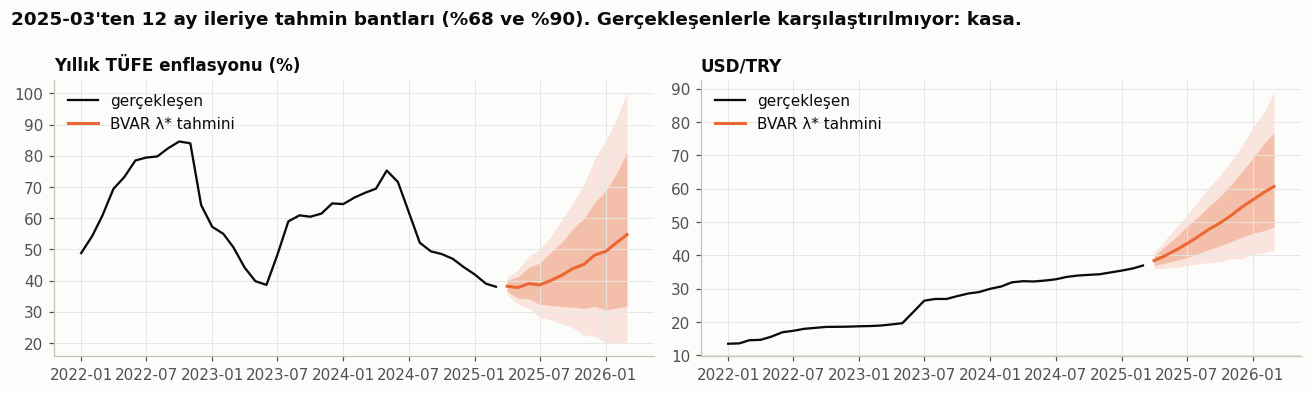

%90 bandının genişliği, 12. ay:


,"yıllık TÜFE, 12. ay (puan)","USD/TRY, 12. ay (%)"
"λ = 0,02 (çok sıkı)",44.9,71.5
"λ* = 0,29 (veri seçti)",80.5,78.2
λ = 10 (≈ OLS),85.2,98.2


In [17]:
def yillik_enflasyon(log_tufe):
    # 100×log TÜFE serisinden yıllık % değişim
    return 100 * (np.exp((log_tufe[12:] - log_tufe[:-12]) / 100) - 1)


tarih_gelecek = pd.date_range(veri.index[-1] + pd.offsets.MonthBegin(1), periods=12, freq="MS")
gecmis_tufe = veri["tufe"].values
fig, eksen = plt.subplots(1, 2, figsize=(12, 3.6))
genislik = {}
for ad, (m, B_ler, S_ler) in CEKILIS.items():
    yollar = tahmin_yollari(B_ler, S_ler, m["Y_son"], ufuk=12)
    # yıllık enflasyon: her yolun başına son 12 ayın gerçekleşmesini ekle
    tufe_yol = np.hstack([np.tile(gecmis_tufe[-12:], (len(yollar), 1)), yollar[:, :, TUFE]])
    enf = np.array([yillik_enflasyon(t) for t in tufe_yol])
    kur = np.exp(yollar[:, :, KUR] / 100)
    genislik[ad] = {"yıllık TÜFE, 12. ay (puan)": np.subtract(*np.percentile(enf[:, -1], [95, 5])),
                    "USD/TRY, 12. ay (%)": 100 * np.subtract(*np.percentile(kur[:, -1], [95, 5])) / np.median(kur[:, -1])}
    if ad.startswith("λ*"):
        enf_yildiz, kur_yildiz = enf, kur

gecmis_enf = pd.Series(yillik_enflasyon(gecmis_tufe), index=veri.index[12:])
ax = eksen[0]
ax.plot(gecmis_enf.loc["2022-01":].index, gecmis_enf.loc["2022-01":], color="#0b0b0b", lw=1.5, label="gerçekleşen")
bant_ciz(ax, tarih_gelecek, enf_yildiz, RENK["turuncu"], etiket=f"BVAR λ* tahmini")
ax.set_title("Yıllık TÜFE enflasyonu (%)", loc="left"); ax.legend()
ax = eksen[1]
ax.plot(ham.loc["2022-01":].index, ham.loc["2022-01":, "usdtry"], color="#0b0b0b", lw=1.5, label="gerçekleşen")
bant_ciz(ax, tarih_gelecek, kur_yildiz, RENK["turuncu"], etiket="BVAR λ* tahmini")
ax.set_title("USD/TRY", loc="left"); ax.legend()
fig.suptitle("2025-03'ten 12 ay ileriye tahmin bantları (%68 ve %90). Gerçekleşenlerle karşılaştırılmıyor: kasa.",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

print("%90 bandının genişliği, 12. ay:")
display(pd.DataFrame(genislik).T.round(1))

Üç gözlem:

1. **Bantlar λ ile genişliyor.** Tabloda λ = 0,02 en dar, λ = 10 en geniş. Gevşek prior parametre belirsizliğini artırıyor ve bu belirsizlik ufukla birikiyor.
   Ama dar bant "daha iyi" demek değil: sıkı prior'ın güveni varsayımdan geliyor. Etki-tepkilerdeki dersin aynısı.
2. **Bantlar çok geniş.** 12 ay sonra yıllık enflasyonun %90 bandı 80 puandan geniş. Sebeplerden biri sabit varyans: model, 2018 ve 2021 kriz aylarının şoklarını "ortalama bir ayın şoku" sayıyor.
   2025 başı gibi görece sakin bir dönemden yapılan tahminde bu bantları fazla genişletir (10. bölüm).
3. **Medyan yükseliyor.** Model hem kurun hızlanacağını hem enflasyonun yükseleceğini öngörüyor. Bunun bir kısmı başlangıç koşullarından geliyor:
   son aylarda AOFM düşüyordu, 2024'te de kur TÜFE'den çok daha yavaş artmıştı. Örneklemde faiz indirimlerini sert değer kayıpları izledi (en belirgin örnek 2021 sonu).
   Ama bu iki etkiyi çıkarınca bile tahminin büyük kısmı kalıyor (Alıştırma 6). Muhtemel sebep, modelin 2021-2023 yüksek enflasyon dinamiğini taşıması:
   2024'te başlayan dezenflasyon politikası, örneklem açısından yeni bir rejim. Bir başka aday, düzeydeki VAR'da sabit terimin taşıdığı sürüklenme; Sims ve Zha'nın (1998) toplam katsayı prior'ı bunun için önerildi.

Bu, BVAR'ın sınırı hakkında önemli bir ders: **model ancak örneklemde gördüğü dinamikleri geleceğe taşır.** Rejim değiştiğinde iyi kurulmuş bir prior bile bunu bilemez.

<details><summary><b>Kendini sına:</b> λ*'ı tüm veriyle seçtik. Bu, örneklem dışı bir tahmin testinde neden "hile" sayılabilir?</summary>

λ* seçimi de veriden öğrenilen bir parametre. Örneklem dışı bir testte λ'yı her tahmin noktasında, **yalnızca o güne kadarki** veriyle yeniden seçmek gerekir.
Aksi halde gelecekteki veri, λ üzerinden geçmişe sızar. Projede test motorunun yaptığı kesme işinin sebebi de bu.
</details>

## 9. Kur geçişkenliği

### Tanımlama: "kur şoku" nedir?

VAR'ın artıkları ($u_t$) birbiriyle ilişkili: aynı ay hem kur hem TÜFE sürprizle yükselebilir. Hangisi hangisine yol açtı? Veri tek başına söyleyemez; bir **varsayım** gerekir.
En yaygın varsayım **Cholesky sıralaması**: değişkenleri sıraya dizer ve "sıradaki değişken, kendinden sonrakilerin şoklarına ancak bir ay gecikmeyle tepki verir" deriz.

Bizim sıramız: **sanayi üretimi → USD/TRY → TÜFE → AOFM**

- Kur şoku TÜFE'yi **aynı ay** etkileyebilir (fiyat etiketleri hızlı değişebilir).
- TÜFE sürprizi kuru aynı ay etkilemez (kur, aylık TÜFE açıklanmadan önce oluşur).
- AOFM her şeye aynı ay tepki verebilir (merkez bankası ay içinde kurdaki hareketi görür).
- Sanayi üretimi aynı ay içinde hiçbir şoka tepki vermez (üretim planları yavaş değişir).

Bunların her biri tartışılabilir. Aşağıda sıralamayı değiştirip sonucun ne kadar oynadığına da bakacağız.

### Geçişkenlik oranı

Kur şokundan sonra kurun kendisi de hareket etmeye devam eder (geri çekilebilir ya da daha da artabilir). Bu yüzden literatürde geçişkenlik bir oran olarak ölçülür:

$$\text{PT}(h) = \frac{\text{TÜFE'nin } h \text{ aydaki birikimli tepkisi}}{\text{kurun } h \text{ aydaki birikimli tepkisi}}$$

Düzeyde çalıştığımız için etki-tepkiler zaten birikimli. PT(12) = 0,4 şu demek: "12 ay sonra kur kalıcı olarak %10 yüksekse, fiyat düzeyi %4 yüksek".

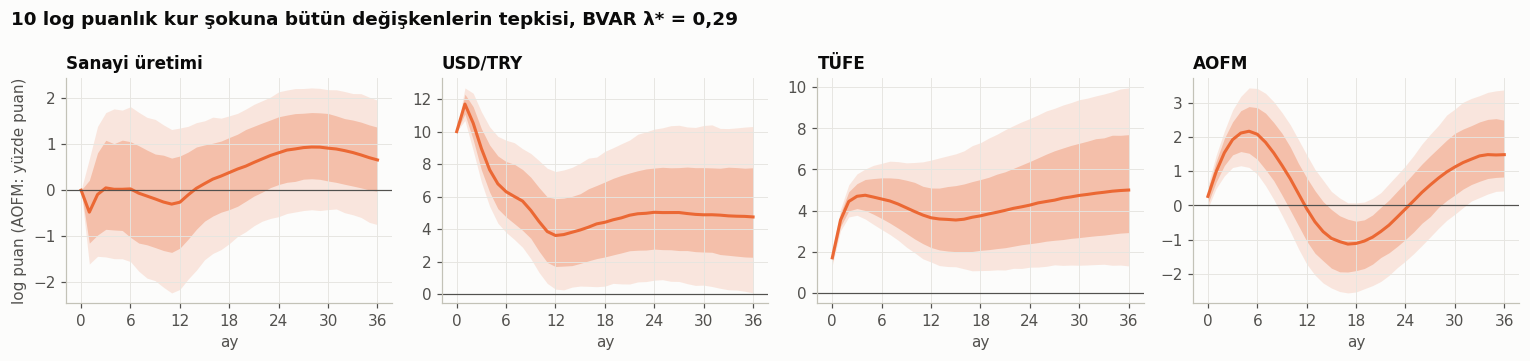

In [18]:
m_y, B_y, S_y = CEKILIS[[k for k in CEKILIS if k.startswith("λ*")][0]]
ET = np.array([etki_tepki(B, S, 4, P, KUR) for B, S in zip(B_y, S_y)])

fig, eksen = plt.subplots(1, 4, figsize=(14, 3.3))
for ax, j in zip(eksen, range(4)):
    bant_ciz(ax, ufuk, ET[:, :, j], RENK["turuncu"])
    ax.axhline(0, color=RENK["gri"], lw=0.8)
    ax.set_title(AD[DEGISKENLER[j]], loc="left"); ax.set_xlabel("ay"); ax.set_xticks(range(0, 37, 6))
eksen[0].set_ylabel("log puan (AOFM: yüzde puan)")
fig.suptitle(f"10 log puanlık kur şokuna bütün değişkenlerin tepkisi, BVAR λ* = {tr(LAM_YILDIZ)}", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

Dört panelin hikâyesi (bantlarla birlikte oku):

- **USD/TRY:** Şok 10 log puanla başlıyor, bir ay sonra 11-12'ye çıkıyor, sonra hızla geri çekiliyor: 12. ayda 4 civarında. Şokun kabaca üçte biri kalıcı.
- **TÜFE:** İlk 3-4 ayda 4,5-5 log puana yükseliyor, kur geri çekilirken bir miktar düşüyor, sonra yavaşça artıyor.
- **AOFM:** İlk aylarda 2 puan civarında yükseliyor (sıkılaşma), bir yıl sonra baz çizgisinin altına iniyor. Bu örneklemde (2021 indirimleri dahil) tek bir sabit politika tepki fonksiyonu varsaymak özellikle sorunlu; bu paneli ihtiyatla oku.
- **Sanayi üretimi:** Bantlar çoğu ufukta sıfırı kapsıyor; belirgin bir etki yok.

Şimdi geçişkenlik oranı:

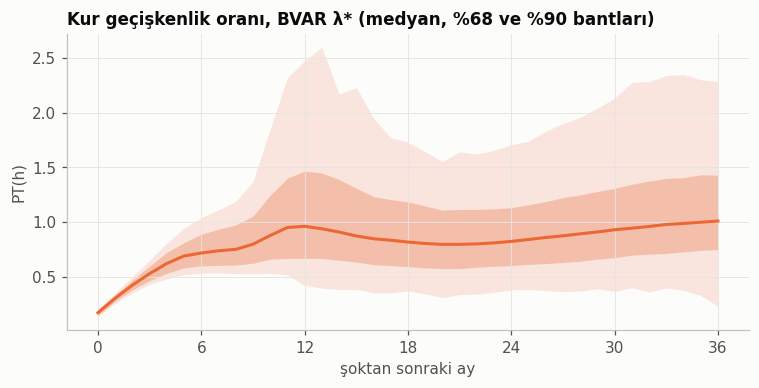

,%5,%16,medyan,%84,%95
ay,,,,,
0,0.13,0.15,0.17,0.19,0.20
3,0.43,0.46,0.53,0.60,0.65
6,0.53,0.60,0.72,0.89,1.04
12,0.42,0.67,0.96,1.47,2.47
24,0.38,0.60,0.82,1.13,1.71
36,0.23,0.75,1.01,1.43,2.29


In [19]:
def gecis_orani(et):
    return et[:, :, TUFE] / et[:, :, KUR]


PT = gecis_orani(ET)
fig, ax = plt.subplots(figsize=(8, 3.5))
bant_ciz(ax, ufuk, PT, RENK["turuncu"])
ax.set_xticks(range(0, 37, 6)); ax.set_xlabel("şoktan sonraki ay"); ax.set_ylabel("PT(h)")
ax.set_title("Kur geçişkenlik oranı, BVAR λ* (medyan, %68 ve %90 bantları)", loc="left")
plt.show()

tablo_pt = pd.DataFrame({h: np.percentile(PT[:, h], [5, 16, 50, 84, 95]) for h in [0, 3, 6, 12, 24, 36]},
                        index=["%5", "%16", "medyan", "%84", "%95"]).T
tablo_pt.index.name = "ay"
tablo_pt.round(2)

Tablodaki aralıklar bu dersin asıl çıktısı: tek bir sayı değil, bir dağılım. "Geçişkenlik X'tir" değil, "veri ve bu varsayımlar altında geçişkenlik büyük olasılıkla şu aralıktadır".

Kısa vadede (ilk birkaç ay) bant görece dar; ufuk uzadıkça genişliyor.

**PT(12)'nin medyanı 1'e yakın. Dikkat:** Bu "tam geçişkenlik" gibi okunabilir, ama oran TÜFE çok yükseldiği için değil, **payda (kur) geri çekildiği için** büyük.
12. ayda TÜFE ve kur ikisi de 3,5-4 log puan civarında yukarıda. Oranı hep pay ve paydayla birlikte oku.
Uzun ufuklarda %95 sınırının 2'yi aşması da bundan: paydanın sıfıra yaklaştığı çekilişlerde oran patlıyor.

### Sıralama duyarlılığı

Kuru sıranın en sonuna alalım: **sanayi üretimi → TÜFE → AOFM → USD/TRY**. Artık kur, her şoka aynı ay tepki veriyor; kur şoku ise TÜFE'yi ancak bir ay sonra etkileyebiliyor.
**Aynı çekilişleri** kullanıyoruz; tek değişen tanımlama varsayımı.

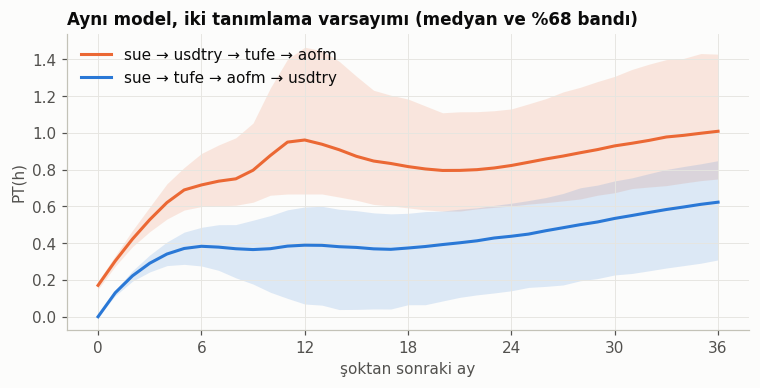

ay  0:  ana sıralama medyan 0.17   alternatif 0.00
ay  3:  ana sıralama medyan 0.53   alternatif 0.29
ay 12:  ana sıralama medyan 0.96   alternatif 0.39
ay 24:  ana sıralama medyan 0.82   alternatif 0.44


In [20]:
SIRA_ALT = [DEGISKENLER.index(v) for v in ["sue", "tufe", "aofm", "usdtry"]]
ET_alt = np.array([etki_tepki(B, S, 4, P, KUR, sira=SIRA_ALT) for B, S in zip(B_y, S_y)])
PT_alt = gecis_orani(ET_alt)

fig, ax = plt.subplots(figsize=(8, 3.5))
bant_ciz(ax, ufuk, PT, RENK["turuncu"], etiket="sue → usdtry → tufe → aofm", bantlar=((16, 84),))
bant_ciz(ax, ufuk, PT_alt, RENK["mavi"], etiket="sue → tufe → aofm → usdtry", bantlar=((16, 84),))
ax.set_xticks(range(0, 37, 6)); ax.set_xlabel("şoktan sonraki ay"); ax.set_ylabel("PT(h)")
ax.set_title("Aynı model, iki tanımlama varsayımı (medyan ve %68 bandı)", loc="left"); ax.legend()
plt.show()
for h in [0, 3, 12, 24]:
    print(f"ay {h:2d}:  ana sıralama medyan {np.median(PT[:, h]):.2f}   alternatif {np.median(PT_alt[:, h]):.2f}")

İlk ay için fark tanım gereği: alternatif sıralamada kur şoku TÜFE'yi aynı ay hiç etkileyemez, PT(0) = 0.
Asıl soru, iki eğrinin sonra yakınlaşıp yakınlaşmadığı. **Yakınlaşmıyorlar.** 12. ayda medyanlar kabaca 1'e karşı 0,4; %68 bantları bile ayrık.
Bu modelde orta vadeli geçişkenlik sonucu, büyük ölçüde tanımlama varsayımından geliyor.

Neden bu kadar fark? Kur ve TÜFE çoğu ay **birlikte** sürpriz yapıyor (aylık artıklar ilişkili). Ana sıralama bu ortak hareketi "kur şoku → fiyatlar" diye okuyor.
Alternatif sıralama aynı hareketi "fiyat şoku → kur" diye okuyor. Veri tek başına hangisinin doğru olduğunu söyleyemez; söyleyen, bizim varsayımımız.

Bu, mutlaka raporlanması gereken bir duyarlılık. Daha sağlam bir yaklaşım işaret kısıtları (*sign restrictions*): "kur şoku kuru ve fiyatları artırır, faizi düşürmez" gibi daha zayıf varsayımlarla, tek bir sıralamaya bağlı kalmadan tanımlama. Ya da tanımlamayı modelin dışından getirmek: örneğin küresel bir dolar şoku gibi, Türkiye'deki fiyatlardan etkilenmediğinden emin olduğumuz bir dış değişken.

### Dönem karşılaştırması: BVAR'ın asıl gösterdiği yer

Geçişkenliğin 2018 sonrasında arttığı sıkça söylenir. Örneklemi ikiye bölelim: **2011-01..2017-12** ve **2018-01..2025-03**.
Her parçada etkin gözlem sayısı 72 ve 75; her denklemde ise 49 katsayı var. OLS burada ya çok gürültülü olur ya hiç çalışmaz. BVAR rahatça çalışır, ve λ'yı her dönem için ayrıca seçeriz.

2011-01 .. 2017-12: etkin gözlem 72, denklem başına katsayı 49, λ* = 0.19, atılan çekiliş 4%, PT(12) medyan 0.36 [%68: -0.16 - 0.94]
2018-01 .. 2025-03: etkin gözlem 75, denklem başına katsayı 49, λ* = 0.26, atılan çekiliş 4%, PT(12) medyan 0.97 [%68: 0.83 - 1.26]


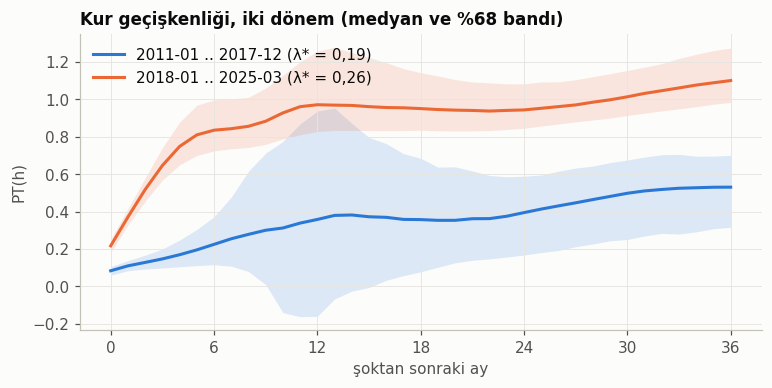

In [21]:
DONEMLER = {"2011-01 .. 2017-12": veri.loc[:"2017-12"].values, "2018-01 .. 2025-03": veri.loc["2018-01":].values}
fig, ax = plt.subplots(figsize=(8, 3.5))
for (ad, Yd_), renk in zip(DONEMLER.items(), [RENK["mavi"], RENK["turuncu"]]):
    T_etkin = len(Yd_) - P
    lam_d = lam_ml[np.argmax([bvar_kur(Yd_, P, l)["log_ml"] for l in lam_ml])]
    m_d = bvar_kur(Yd_, P, lam_d)
    B_d, S_d, atilan_d = cekilisler(m_d, adet=1000)
    PT_d = gecis_orani(np.array([etki_tepki(B, S, 4, P, KUR) for B, S in zip(B_d, S_d)]))
    bant_ciz(ax, ufuk, PT_d, renk, etiket=f"{ad} (λ* = {tr(lam_d)})", bantlar=((16, 84),))
    print(f"{ad}: etkin gözlem {T_etkin}, denklem başına katsayı {4 * P + 1}, λ* = {lam_d:.2f}, "
          f"atılan çekiliş {atilan_d:.0%}, PT(12) medyan {np.median(PT_d[:, 12]):.2f} "
          f"[%68: {np.percentile(PT_d[:, 12], 16):.2f} - {np.percentile(PT_d[:, 12], 84):.2f}]")
ax.set_xticks(range(0, 37, 6)); ax.set_xlabel("şoktan sonraki ay"); ax.set_ylabel("PT(h)")
ax.set_title("Kur geçişkenliği, iki dönem (medyan ve %68 bandı)", loc="left"); ax.legend(loc="upper left")
plt.show()

2018 sonrası dönemde geçişkenlik belirgin biçimde daha yüksek görünüyor: PT(12) medyanı 1'e yakın, ilk dönemde 0,4'ün altında.
İlk dönemin bandı çok geniş, bir ara sıfırın altına bile iniyor. Bu, oranın kırılganlığından: o dönemde bazı çekilişlerde kurun kendi tepkisi sıfıra yaklaşıyor.

Sonucu okurken dört uyarı:

1. **Bantların örtüşmesine bak.** 12. ay civarında bantlar az da olsa örtüşüyor; daha uzun ufuklarda ayrışıyor. Medyanlar arasındaki fark tek başına bir şey kanıtlamaz.
2. **λ* dönemlere göre değişti.** İki kısa örneklemde de veri, tam örneklemdekinden (0,29) daha sıkı bir prior seçti. Kısa örneklemde veri daha az bilgi taşır; prior daha çok konuşur. Sıkı prior iki dönemi birbirine (ve rassal yürüyüşe) benzetir, yani farkı bastırma eğilimindedir.
3. **Tek bir tanımlama kullandık.** Az önce sonucun sıralamaya çok duyarlı olduğunu gördük. Dönem farkı alternatif sıralamada da duruyor mu? Alıştırma 7.
4. **Bu bir bulgu değil.** Dönem ayrımını grafiğe bakarak seçtik, ilk açıklanan veri kullanmadık. Gerçek bir araştırma sorusu olsaydı önce hipotez kartı yazılır, kriter test öncesi sabitlenirdi.

<details><summary><b>Kendini sına:</b> Dönemleri ayırmak yerine, "zamanla değişen geçişkenlik"i nasıl modellerdin?</summary>

İki yaygın yol var: (1) **Kayan pencere**: örneğin 7 yıllık pencereyi aydan aya kaydırıp her pencerede BVAR tahmin etmek. Basit ama pencere boyu keyfi.
(2) **Zamanla değişen parametreli VAR** (TVP-VAR, Primiceri 2005): katsayıların her ay küçük bir rassal yürüyüşle değiştiği bir model. Daha zarif ama çok daha ağır (Gibbs örneklemesi gerekir).
</details>

## 10. Türkiye verisinde tuzaklar

Kurduğumuz model ders için iyi bir başlangıç, ama Türkiye verisinde birkaç varsayımı zorlanıyor. Biri en görünür olanı: **sabit varyans**.

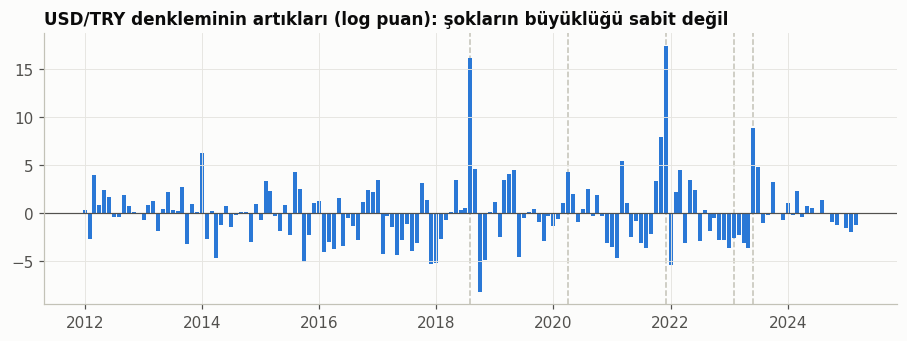

Yıllara göre kur şoklarının standart sapması (log puan):


tarih,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
std,1.7,1.6,2.7,2.7,2.5,2.9,6.2,2.8,2.0,6.5,3.1,3.8,1.0


In [22]:
Yf, Xf = gecikme_matrisi(Y_tum, P)
artik = pd.DataFrame(Yf - Xf @ m_y["B"], index=veri.index[P:], columns=DEGISKENLER)

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(artik.index, artik["usdtry"], width=25, color=RENK["mavi"])
ax.axhline(0, color=RENK["gri"], lw=0.8)
for t, etiket in KIRILMALAR.items():
    ax.axvline(pd.Timestamp(t), color=RENK["acik_gri"], lw=1, ls="--", zorder=0)
ax.set_title("USD/TRY denkleminin artıkları (log puan): şokların büyüklüğü sabit değil", loc="left")
plt.show()
gruplar = artik["usdtry"].groupby(artik.index.year)
oynaklik = gruplar.std()[gruplar.size() >= 6]          # 2025'te yalnız 3 ay var; dışarıda bırak
print("Yıllara göre kur şoklarının standart sapması (log puan):")
display(oynaklik.round(1).to_frame("std").T)

Model her ay aynı büyüklükte şok bekliyor ($\Sigma$ sabit). Gerçekte 2018 ve 2021'de kur şoklarının std'si 6 log puanı aşıyor, 2024'te 1'in altına iniyor: altı kattan fazla fark. Sonuçları:

| Tuzak | Ne bozuluyor | Ne yapılır |
|---|---|---|
| **Sabit varyans** | Sakin dönemlerde bantlar fazla geniş, kriz dönemlerinde fazla dar. Kriz ayları katsayıları orantısız etkiliyor. | Stokastik oynaklıklı BVAR (BVAR-SV; Clark 2011, Carriero vd. 2019) |
| **Rejim değişikliği** | 2021 indirimleri ve 2023 dönüşü gibi politika değişikliklerinde katsayılar aynı kalmıyor (Lucas eleştirisi). | Kayan pencere, TVP-VAR, kırılma kuklaları |
| **COVID ayları** | 2020 baharı birkaç gözlemle katsayıları çekiyor; sanayi üretiminin σ'sını (dolayısıyla prior ölçeğini) şişiriyor. | Lenza ve Primiceri (2022): o aylarda varyansı ölçekleyen bir parametre |
| **Tanımlama** | Geçişkenlik, Cholesky sırasına bağlı. | Sıralama duyarlılığı raporla; işaret kısıtları |
| **Revize veri** | EVDS güncel değerleri veriyor; o gün bilinen değer başkaydı. | Gerçek zamanlı (vintage) veri; projede "ilk açıklanan" kuralı |
| **Patlayan çekilişler** | Düzeyde VAR'da bazı çekilişler patlayıcı kök taşıyor; attık. Atılan pay büyükse sonuçlar seçime duyarlı. | Atılan payı raporla; toplam katsayı (*sum-of-coefficients*) prior'ı (Sims ve Zha 1998) |
| **λ seçimi** | λ*'ı tüm veriyle seçtik; λ belirsizliğini yok saydık. | Hiyerarşik BVAR: λ'ya da prior koy, onu da örnekle (Giannone, Lenza ve Primiceri 2015) |

## 11. Alıştırmalar

Her alıştırma için yeni bir hücre aç; gerekirse yukarıdaki fonksiyonları kullan. İpuçları ve ne görmeyi beklemen gerektiği katlı.

**Alıştırma 1: Gecikme sayısı.** `P = 6` ile 8. bölümdeki marjinal olabilirlik eğrisini ve 9. bölümdeki PT(12)'yi yeniden hesapla. λ* ve geçişkenlik değişiyor mu?

<details><summary>İpucu</summary>

`bvar_kur(Y_tum, 6, lam)` kullan; `etki_tepki(..., p=6)` ve `cekilisler` de modelin `p`'siyle çalışır. Farklı p'lerin marjinal olabilirliklerini karşılaştırırken dikkat: Y'nin uzunluğu değiştiği için (ilk p gözlem düşüyor) karşılaştırmayı aynı örneklemde yapmak için ikisini de aynı başlangıç ayından başlat.
</details>

**Alıştırma 2: Gecikme sönümü.** `d = 2` ile (`bvar_kur(..., d=2)`) prior ısı haritasını ve λ*'ı yeniden hesapla. Marjinal olabilirlik hangi d'yi tercih ediyor?

<details><summary>İpucu</summary>

d büyüdükçe uzak gecikmeler daha sert sıfıra çekilir. Bu, λ'nın daha büyük seçilmesine izin verebilir: yakın gecikmeler serbest, uzaklar sıkı. Bir (λ, d) ızgarası üzerinde log ML'yi hesaplayıp ısı haritası çiz.
</details>

**Alıştırma 3: Fark mı, düzey mi?** Kur ve TÜFE'yi aylık log farka (`veri.diff()`), AOFM'yi düzeyde bırak. Fark alınan seriler için `delta = 0`, AOFM için `delta = 1` kullan. Geçişkenlik oranını hesaplamak için etki-tepkileri **birikimli toplaman** gerekir. Sonuç düzey modelinkine benziyor mu?

<details><summary>Beklenen gözlem</summary>

Farkta çalışan model kalıcı etkileri "unutmaz", ama düzeyler arasındaki uzun vadeli ilişkiyi de kullanmaz. Kısa vadeli geçişkenlik genelde benzer çıkar; uzun ufuklarda ayrışabilir.
</details>

**Alıştırma 4: Beşinci değişken.** EVDS'den imalat sanayi kapasite kullanım oranını (`bie_kkoisma` veri grubu, mevsimsellikten arındırılmış) çek, modele ekle. Kaç katsayı oldu? λ* nasıl değişti?

<details><summary>İpucu</summary>

`veri_cek.py` içindeki `SERILER` sözlüğüne bir satır ekle. Değişken sayısı arttıkça marjinal olabilirlik genelde daha küçük bir λ seçer: daha büyük modeller daha fazla küçültme ister (Bańbura vd. 2010'un ana bulgularından biri).
</details>

**Alıştırma 5: Örneklem büyüklüğü.** 7. bölümde `T_egitim = 400` yap. U eğrisinin dibi sağa mı kayıyor? BVAR ile OLS arasındaki fark ne oldu?

<details><summary>Beklenen gözlem</summary>

Dip sağa kayar (daha gevşek prior), OLS ile fark daralır. Çok veride küçültmeye daha az ihtiyaç vardır.
</details>

**Alıştırma 6: Tahmini ne yukarı itiyor?** 8. bölümdeki tahminin medyanı hem kurda hem enflasyonda yükseliyordu. Başlangıç koşullarını değiştirip **şoksuz nokta tahmini** yap:
(a) `Y_son`'da AOFM'yi son 12 ay boyunca 50'de sabit tut, (b) kuru son 12 ayda TÜFE kadar artmış gibi yeniden yaz, (c) ikisini birden yap. Her durumda 12 aylık kur ve TÜFE artışına bak.

<details><summary>İpucu ve beklenen gözlem</summary>

Nokta tahmin için `tahmin_yollari` yerine, posterior ortalaması `B` ile `y = x @ B` döngüsünü şoksuz çalıştır. `Y_son = m_y["Y_son"].copy()`; sütun sırası `DEGISKENLER`.
Kabaca şunu görmelisin: (a) kur tahminini belirgin, TÜFE tahminini daha az düşürür; (b) çoğunlukla kur tahminini düşürür.
İkisi birlikte 12 aylık kur artışını %65-70 civarından %45 civarına, TÜFE artışını %55 civarından %47 civarına indirir. Yine de ikisi de %40'ın üzerinde kalır.
Yani başlangıç koşulları tahminin yalnızca bir kısmını açıklıyor; gerisi modelin örneklemden öğrendiği dinamik.
</details>

**Alıştırma 7: Dönem farkı tanımlamaya dayanıklı mı?** 9. bölümdeki dönem karşılaştırmasını alternatif sıralamayla (`sira=SIRA_ALT`) tekrarla.

<details><summary>Neye bakmalı</summary>

Fark alternatif sıralamada da duruyorsa, dönem sonucu tanımlamaya daha az duyarlı demektir. Kaybolur ya da çok küçülürse, gördüğümüz dönem farkının bir kısmı tanımlamanın eseridir.
Her iki durumda da bu, raporlanacak bir sonuç: "iki tanımlamada da" ya da "yalnızca bir tanımlamada".
</details>

## 12. Özet ve ileri okuma

**Bu derste öğrendiklerin:**

- VAR'da katsayı sayısı $n^2p$ ile büyür. Türkiye'nin kısa makro serilerinde klasik VAR gürültüyü ezberler: testere dişi katsayılar, oynak tahminler.
- Bayesçi küçültme, veriyle prior'ın **hassasiyet ağırlıklı ortalamasıdır**. Prior, sahte gözlem olarak veriye eklenebilir; sonra sıradan OLS yeterli.
- Minnesota prior'ı "her seri kendi geçmişini izler, başkalarının etkisi küçük ve uzak gecikmelerde daha küçük" der. Bütün sıkılığını tek bir λ ayarlar.
- λ küçüldükçe önyargı artar, büyüdükçe varyans artar. Marjinal olabilirlik, ne gerçeği ne de test verisini görmeden iyi bir dengeyi bulabiliyor.
- Etki-tepki ve geçişkenlik gibi "yapısal" sorular ayrıca bir tanımlama varsayımı ister. Bu derste sonuç sıralamaya çok duyarlı çıktı: 12 ayda geçişkenlik bir sıralamada 1'e yakın, ötekinde 0,4 civarında. Bu duyarlılık raporlanır.
- BVAR'ın çıktısı tek bir sayı değil, bir dağılımdır. Bantlar hem şok belirsizliğini hem de parametre belirsizliğini taşır. Dar bant, yalnızca prior'ın güvenini yansıtıyor olabilir.
- Model ancak örneklemde gördüğü dinamiği geleceğe taşır. Türkiye gibi rejimlerin sık değiştiği bir ekonomide sabit katsayı ve sabit varyans en zayıf halkalar.

**Bu laboratuvarla bağlantısı.** BVAR, nowcast çalışmalarında güçlü bir **kıyas modeli**: bir alternatif veri göstergesinin değer kattığını söylemek için, iyi kurulmuş bir BVAR'ı geçmesi gerekir. Bunu yapmak istersek yol belli: hipotez kartı, test öncesi kriter, `src/analiz/test_et.py`.

**İleri okuma** (kabaca kolaydan zora):

- Litterman, R. (1986). *Forecasting with Bayesian vector autoregressions: Five years of experience.* Journal of Business & Economic Statistics. Minnesota prior'ının doğuşu.
- Koop, G. ve Korobilis, D. (2010). *Bayesian multivariate time series methods for empirical macroeconomics.* Kodlu, kapsamlı bir giriş.
- Bańbura, M., Giannone, D. ve Reichlin, L. (2010). *Large Bayesian vector auto regressions.* Journal of Applied Econometrics. Bu dersteki sahte gözlem yapısı.
- Giannone, D., Lenza, M. ve Primiceri, G. (2015). *Prior selection for vector autoregressions.* Review of Economics and Statistics. λ'yı marjinal olabilirlikle seçmenin hiyerarşik sürümü.
- Sims, C. ve Zha, T. (1998). *Bayesian methods for dynamic multivariate models.* International Economic Review. Toplam katsayı ve tek birim kök prior'ları.
- Lenza, M. ve Primiceri, G. (2022). *How to estimate a vector autoregression after March 2020.* Journal of Applied Econometrics. COVID aylarıyla başa çıkmak.
- Kuschnig, N. ve Vashold, L. (2021). *BVAR: Bayesian vector autoregressions with hierarchical prior selection in R.* Journal of Statistical Software. Bu dersin hiyerarşik sürümünü hazır sunan R paketi; sonuçlarını çapraz kontrol için kullanabilirsin.